# Experiment log

One section per experiment: **question → runs → a few fixed plots → conclusion**. Training curves come from
W&B (cached under `results/experiments/wandb_cache/`); evaluation results come from the JSON dumps in `results/`.

| # | Date | Question | Status | Conclusion |
|---|---|---|---|---|
| 1 | 2026-11-05 → 11-10 | Can TabPFN-3.5 Fast or Kumo-small replace TabICL as the copula's marginal? | done | Only once ERA5-finetuned like TabICL. Then TabPFN-3.5 Fast (ERA5-finetuned) + copula is best: val total $1.236$ vs $1.261$ (TabICL v2, ERA5-finetuned), $1.334$ (Kumo-small, ERA5-finetuned) |
| 2 | 2026-11-04 → | Does the synthetic-trained copula help on new real regression datasets? | `sdwpf_f0_block` left (3/4 folds) | Beats independence in 64/71 cells and 16/24 full CTR23 datasets; loses to autoregressive in 41/71. On CTR23 every ERA5-finetuned marginal loses to its pretrained version (23–24/24 datasets) |
| 3 | 2026-11-09 → | Does training on variable $(P, N)$ give a copula that helps at every size? | 4 runs at 70–95 k, `PRE_nano_PN_kumo` at 5 k | Captures 2–9 % of the oracle copula gain on the size grid; the gain is at small $P$ / large $N$, $\approx 0$ at $P \ge 316$ and at $N = 10$ |
| 5 | 2026-11-17 → | Under BeyondArena's official protocol (TabArena preprocessing, refit bagging, whole test fold, no group ID), does the copula improve the joint predictive of 6 marginals on grouped, temporal and IID tasks? | large tables running (TabPFN, Kumo); TabICL maps_router out of memory | Joint NLL: copula ≤ independence for every marginal (Elo +19 to +139); on grouped tasks it captures little of the within-group correlation (ρ̄ 0.004–0.12 vs 0.6 measured), below the group-aware exchangeable reference. The marginal dominates: every pretrained marginal outranks every ERA5-finetuned one |

The final-step tables come from the **wandb-results** skill's runner (`eval.runners.wandb_report`, main checkout),
called through `wandb_report(name, *overrides)` and cached in `results/experiments/wandb_report_<name>.json`.

**Conventions.** NLLs are per-point, in nats, on the raw $y$ scale:
$\text{NLL}_\text{total} = \text{NLL}_\text{marginal} + \text{NLL}_\text{copula}$. When comparing methods, read the
**total**. A delta $\Delta = \text{NLL}_\text{copula model} - \text{NLL}_\text{ref}$ is **negative when the copula is better**.

**Adding an experiment.** Add a row to the table, a markdown cell (question, setup, what differs between runs),
a code cell that maps labels to W&B run ids or to dump globs, then call the plot helpers (`plot_nll_curves`,
`final_val`, …). Write the conclusion once the runs finish. W&B caches of finished runs are never refetched.

**How to run.** W&B credentials and the dumps live on the cluster. Run the notebook on a Grid5000 node, from this
worktree, inside an OAR job:
```bash
source scripts/_env.sh && uv run --active --no-sync --with nbconvert --with ipykernel jupyter nbconvert \
    --to notebook --execute --inplace notebooks/experiments.ipynb --ExecutePreprocessor.kernel_name=python3
```
Then open the saved notebook in VS Code. Set `REFRESH = True` to refetch runs that have finished.

In [1]:
# --- setup ---
import functools
import glob
import hashlib
import json
import os
import re
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.lines import Line2D

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "eval/runners/paired_compare.py").exists())
for p in (ROOT / "tabicl_upstream/src", ROOT, ROOT / "src"):  # ends as src, ROOT, tabicl first
    if str(p) in sys.path:
        sys.path.remove(str(p))
    sys.path.insert(0, str(p))

from eval.runners.paired_compare import PairedCompareSpec, within_run_deltas  # noqa: E402

ENTITY = "iliass-lasri-team"
COPULA = f"{ENTITY}/copula-inter-instance"  # copula training runs (train.py)
MARGINAL = f"{ENTITY}/copula-inter-marginal"  # Phase-A marginal finetuning runs (finetune_marginal.py)
CACHE = ROOT / "results/experiments/wandb_cache"
CACHE.mkdir(parents=True, exist_ok=True)
REFRESH = False  # True: refetch finished runs too

# Fixed colour per marginal backend (validated categorical slots 1-3), whatever the plot.
COLORS = {"TabICL": "#2a78d6", "TabPFN": "#eb6834", "Kumo": "#1baf7a"}
# Display names for the figures: the marginal model (colour) and its training state.
MARGINAL_NAME = {"TabICL": "TabICL v2", "TabPFN": "TabPFN-3.5 Fast", "Kumo": "Kumo-small"}
MARGINAL_STATE = {
    "PRE": "pretrained",
    "A": "short-adapted (200–300 steps)",
    "FT": "ERA5-finetuned",
    "PT": "short-adapted (200–300 steps)",
}
COPULA_NOTE = {"PT": "copula resumed from the fixed-size run"}  # other recipes: copula trained from scratch


def run_label(backend: str, recipe: str, sep: str = "; ") -> str:
    """Legend text for a copula run, e.g. 'TabPFN-3.5 Fast, ERA5-finetuned'."""
    note = f"{sep}{COPULA_NOTE[recipe]}" if recipe in COPULA_NOTE else ""
    return f"{MARGINAL_NAME[backend]}, {MARGINAL_STATE[recipe]}{note}"


plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": "#e4e3df",
        "grid.linewidth": 0.6,
        "lines.linewidth": 2,
        "legend.frameon": False,
    }
)
pd.set_option("display.max_rows", 200, "display.width", 200, "display.precision", 4)
print("worktree:", ROOT)

worktree: /srv/storage/thoth1@storage4.grenoble.grid5000.fr/trmartin/copula-inter/.claude/worktrees/real-data-datasets


In [2]:
# --- W&B access with an on-disk cache: finished runs are fetched once ---
@functools.cache
def _api():
    try:
        import wandb

        return wandb.Api(timeout=120)
    except Exception as e:  # no wandb, no credentials, no network
        print(f"W&B API unavailable ({type(e).__name__}: {e}); using the cache only")
        return None


def _flat(d: dict, prefix: str = "") -> dict:
    out = {}
    for k, v in d.items():
        if isinstance(v, dict):
            out.update(_flat(v, f"{prefix}{k}."))
        else:
            out[f"{prefix}{k}"] = v
    return out


def _use_cache(path: Path, state: str | None) -> bool:
    return path.is_file() and (_api() is None or (state not in (None, "running") and not REFRESH))


def run_info(run_id: str, project: str = COPULA) -> dict:
    """Name, state, url, flattened config and numeric summary of a run."""
    path = CACHE / f"{run_id}.json"
    cached = json.loads(path.read_text()) if path.is_file() else None
    if _use_cache(path, cached and cached["state"]):
        return cached
    if _api() is None:
        raise RuntimeError(f"run {run_id} is not cached and the W&B API is unavailable")
    r = _api().run(f"{project}/{run_id}")
    summary = {
        k: v
        for k, v in r.summary._json_dict.items()
        if isinstance(v, (int, float)) and not k.startswith(("gradients/", "parameters/"))
    }
    info = {
        "id": run_id,
        "project": project,
        "name": r.name,
        "state": r.state,
        "created_at": r.created_at,
        "url": r.url,
        "config": _flat(r.config),
        "summary": summary,
    }
    path.write_text(json.dumps(info, default=str))
    return info


def history(run_id: str, keys: list[str], project: str = COPULA) -> pd.DataFrame:
    """Every logged row holding all `keys` (column `step` + keys); empty if a key was never logged."""
    tag = hashlib.sha1(",".join(sorted(keys)).encode()).hexdigest()[:8]
    path = CACHE / f"{run_id}__{tag}.csv"
    state = run_info(run_id, project)["state"]
    meta = path.with_suffix(".state")  # the run's state when the CSV was fetched
    fetched_running = not meta.is_file() or meta.read_text() == "running"
    if _use_cache(path, "running" if fetched_running else state):
        return pd.read_csv(path)
    for attempt in range(3):  # W&B history reads fail transiently (e.g. 403 on a parquet batch)
        try:
            rows = list(_api().run(f"{project}/{run_id}").scan_history(keys=["_step", *keys], page_size=10_000))
            break
        except Exception as e:
            if attempt == 2:
                if path.is_file():
                    print(f"history {run_id}: fetch failed ({type(e).__name__}); using the cached CSV")
                    return pd.read_csv(path)
                raise
    df = pd.DataFrame(rows, columns=["_step", *keys]).rename(columns={"_step": "step"}).sort_values("step")
    df.to_csv(path, index=False)
    meta.write_text(str(state))
    return df


def runs_table(runs: dict[str, str], project: str = COPULA) -> pd.DataFrame:
    """Label, W&B name/state/step and checkpoint dir of each run."""
    rows = []
    for label, rid in runs.items():
        i = run_info(rid, project)
        rows.append(
            {
                "label": label,
                "id": rid,
                "state": i["state"],
                "step": i["summary"].get("_step"),
                "ckpt_dir": i["config"].get("training.ckpt_dir"),
                "url": i["url"],
            }
        )
    return pd.DataFrame(rows).set_index("label")


# Final-step tables come from the wandb-results skill's runner (eval.runners.wandb_report, main checkout):
# full = marginal + copula, copula on exact z, the (P, N) size grid. Records are cached as JSON next to the W&B cache.
REPORT_ROOT = next(p for p in [ROOT, *ROOT.parents] if (p / "eval/runners/wandb_report.py").exists())


def wandb_report(name: str, *overrides: str) -> list[dict]:
    """Records of `python -m eval.runners.wandb_report <overrides>`, cached in results/experiments/wandb_report_<name>.json.

    Rerun when the cache is missing, when REFRESH, or when one of its runs was still running."""
    path = CACHE.parent / f"wandb_report_{name}.json"
    recs = json.loads(path.read_text()) if path.is_file() else None
    if recs is not None and (_api() is None or not (REFRESH or any(r["state"] == "running" for r in recs))):
        return recs
    env = {
        **os.environ,
        "PYTHONPATH": os.pathsep.join(str(REPORT_ROOT / p) for p in ("src", ".", "tabicl_upstream/src")),
    }
    for attempt in range(3):  # W&B history reads fail transiently (e.g. 403 on a parquet batch)
        res = subprocess.run(
            [sys.executable, "-m", "eval.runners.wandb_report", *overrides, f"out={path}"],
            cwd=REPORT_ROOT,
            env=env,
            capture_output=True,
            text=True,
        )
        if res.returncode == 0:
            return json.loads(path.read_text())
    err = res.stderr.strip().splitlines()[-1] if res.stderr.strip() else "?"
    if recs is None:
        raise RuntimeError(res.stderr[-3000:])
    print(f"wandb_report {name}: refresh failed 3 times ({err}); using the cached records")
    return recs


def report_frame(recs: list[dict]) -> pd.DataFrame:
    """One row per run at its last validation step (nats/point): full = marginal + copula, and the size grid."""
    rows = []
    for r in recs:
        last, best, g = r["last"], r["best_full"], r["grid_last"]
        rows.append(
            {
                "run": r["label"],
                "id": r["run_id"],
                "state": r["state"],
                "step": int(last["step"]),
                "marginal (= indep.)": last["marginal"],
                "copula": last["copula"],
                "full": last["full"],
                "excess vs oracle": last["excess"],
                "copula exact z": last["copula_exact"],
                "best full": best["full"],
                "best @": int(best["step"]),
                **({"grid mean": g["mean"], "captured": g["captured"]} if g else {}),
            }
        )
    return pd.DataFrame(rows).set_index("run")

In [3]:
# --- plot helpers for copula training runs ---
TRAIN_KEYS = ["train/y_nll_copula", "train/y_nll_total"]
VAL_KEYS = ["val/y_nll_copula", "val/y_nll_total"]
ORACLE_KEYS = ["val/y_nll_oracle_posterior_copula", "val/y_nll_oracle_posterior"]
PANELS = ["copula NLL", "total NLL (Y-space)"]


def _backend(label: str) -> str:
    return next(b for b in COLORS if label.startswith(b))


def _smooth(y: pd.Series, frac: float = 0.03) -> pd.Series:
    return y.rolling(max(1, int(len(y) * frac)), center=True, min_periods=1).mean()


def _ylim(ax: plt.Axes, values: list[np.ndarray], skip_frac: float = 0.05) -> None:
    # Clip the early-training transient: limits from the 1-99 % range after the first skip_frac of steps.
    v = np.concatenate([x[int(len(x) * skip_frac) :] for x in values if len(x)]) if values else np.array([])
    v = v[np.isfinite(v)]
    if len(v):
        lo, hi = np.percentile(v, [1, 99])
        pad = 0.08 * (hi - lo or 1.0)
        ax.set_ylim(lo - pad, hi + pad)


def plot_nll_curves(
    runs: dict[str, str],
    title: str,
    dashed: tuple[str, ...] = (),
    smooth_frac: float = 0.05,
    logx: bool = False,
    names: dict[str, str] | None = None,
    legend_title: str = "marginal model (source of the copula's z)",
    ncol: int | None = None,
) -> plt.Figure:
    """Rows: train (smoothed) / val; columns: copula / total NLL. Colour = backend; labels in `dashed` dashed.

    `names` maps a run key to its legend text (default: the key)."""
    fig, axes = plt.subplots(2, 2, figsize=(12.5, 7.4), sharex=True)
    seen = {(r, c): [] for r in range(2) for c in range(2)}
    oracle = {0: [], 1: []}
    for label, rid in runs.items():
        style = dict(
            color=COLORS[_backend(label)], ls="--" if label in dashed else "-", label=(names or {}).get(label, label)
        )
        for row, keys in enumerate([TRAIN_KEYS, VAL_KEYS]):
            h = history(rid, keys)
            for col, k in enumerate(keys):
                d = h[["step", k]].dropna()  # W&B rows can miss a key: drop them, or the line breaks
                d = d[d.step > 0] if logx else d
                if not len(d):
                    continue
                y = _smooth(d[k], smooth_frac) if row == 0 else d[k]
                axes[row, col].plot(d.step / 1e3, y, marker=None if row == 0 else "o", ms=3, **style)
                seen[row, col].append(y.to_numpy())
        orc = history(rid, ORACLE_KEYS)
        for col, k in enumerate(ORACLE_KEYS):
            if len(v := orc[k].dropna()):
                oracle[col].append(float(v.iloc[-1]))
    for col in range(2):
        # The GP oracle sits ~1 nat below every run: quoted in the title, not drawn (it would flatten the curves).
        ref = f"   (GP oracle posterior: {np.median(oracle[col]):.3f})" if oracle[col] else ""
        axes[0, col].set_title(f"train · {PANELS[col]}, smoothed", loc="left", fontsize=10)
        axes[1, col].set_title(f"val · {PANELS[col]}{ref}", loc="left", fontsize=10)
        axes[1, col].set_xlabel("step (k)" + (", log scale" if logx else ""))
        if logx:
            axes[0, col].set_xscale("log")
    for (r, c), vals in seen.items():
        _ylim(axes[r, c], vals)
        axes[r, c].set_ylabel("nats / point" if c == 0 else "")
    handles, labels = axes[1, 0].get_legend_handles_labels()
    ncol = ncol or len(labels)
    fig.legend(
        handles,
        labels,
        loc="lower center",
        ncol=ncol,
        fontsize=9,
        bbox_to_anchor=(0.5, 0.0),
        title=legend_title,
        title_fontsize=9,
    )
    fig.suptitle(title, x=0.01, ha="left", fontsize=12)
    fig.tight_layout(rect=(0, 0.06 + 0.03 * -(-len(labels) // ncol), 1, 1))
    return fig


def final_val(runs: dict[str, str]) -> pd.DataFrame:
    """Last logged validation NLLs; gap = total minus the GP oracle posterior on the same episodes."""
    rows = []
    for label, rid in runs.items():
        i = run_info(rid)
        s = i["summary"]
        rows.append(
            {
                "run": label,
                "state": i["state"],
                "step": s.get("_step"),
                "val copula": s.get("val/y_nll_copula"),
                "val marginal": s.get("val/y_nll_marginal"),
                "val total": s.get("val/y_nll_total"),
                "oracle total": s.get("val/y_nll_oracle_posterior"),
            }
        )
    df = pd.DataFrame(rows).set_index("run")
    df["gap to oracle"] = df["val total"] - df["oracle total"]
    return df

---
## 1. Copula with TabPFN-3.5 Fast and Kumo-small marginals

**Question.** The copula is trained on PIT values $z = \Phi^{-1}(F_\theta(y))$ from a marginal model $F_\theta$
(`data.z_train_source`). Can TabPFN-3.5 Fast (`tabpfn35_fast`) or Kumo-small (`kumo_small`) replace TabICL here?

**Setup (branch `marginal-backend-choice`, 2026-11-05/06).** These are copula runs with the same recipe that differ
only in the marginal. The `_A` suffix means the marginal had a *short* Phase-A adaptation, from
`checkpoints/marginal_backend_choice/phase_a_<backend>/step_0000{200,300}_final.pt`.

| Group | Size | Steps | Context |
|---|---|---|---|
| `F_*_A` (full) | nano (336 k params), prod (27 M) | 1 M | $P = 32$, $N = 256$ |
| `R_*_A` | nano, prod | 100 k | same |
| `S_prod_*_A` (scratch) | prod, TabICL backbone | 100 k | same |

In [4]:
E1 = {
    "F nano": {"TabICL": "z9m0qgc9", "TabPFN": "liypqetl", "Kumo": "tc7fpelt"},
    "F prod": {"TabICL": "na7rsa2p", "TabPFN": "g97g8eig", "Kumo": "d9o3tekh"},
    "R nano": {"TabICL": "1wkju1kz", "TabPFN": "u3s4sgu8", "Kumo": "0596fhxc"},
    "R prod": {"TabICL": "rbileqpe", "TabPFN": "ailr9n4l", "Kumo": "vo5kc3lz"},
    "S prod": {"TabICL": "23mvhpwa", "TabPFN": "cpqm827x", "Kumo": "5llzrmzr"},
}
pd.concat({g: runs_table(r) for g, r in E1.items()}, names=["group"])[["id", "state", "step", "ckpt_dir"]]

wandb: [wandb.Api()] Loaded credentials for https://api.wandb.ai from /home/trmartin/.netrc.


id     state     step                                           ckpt_dir
group  label                                                                                 
F nano TabICL  z9m0qgc9  finished  1000000  checkpoints/marginal_backend_choice/full/F_nan...
       TabPFN  liypqetl  finished  1000000  checkpoints/marginal_backend_choice/full/F_nan...
       Kumo    tc7fpelt  finished  1000000  checkpoints/marginal_backend_choice/full/F_nan...
F prod TabICL  na7rsa2p  finished  1000000  checkpoints/marginal_backend_choice/full/F_pro...
       TabPFN  g97g8eig  finished  1000000  checkpoints/marginal_backend_choice/full/F_pro...
       Kumo    d9o3tekh  finished  1000000  checkpoints/marginal_backend_choice/full/F_pro...
R nano TabICL  1wkju1kz  finished   100000  checkpoints/marginal_backend_choice/real/R_nan...
       TabPFN  u3s4sgu8  finished   100000  checkpoints/marginal_backend_choice/real/R_nan...
       Kumo    0596fhxc  finished   100000  checkpoints/marginal_backend_choice/real/R_nan...
R prod TabICL  rbileqpe  finished   100000  checkpoints/marginal_backend_choice/real/R_pro...
       TabPFN  ailr9n4l  finished   100000  checkpoints/marginal_backend_choice/real/R_pro...
       Kumo    vo5kc3lz  finished   100000  checkpoints/marginal_backend_choice/real/R_pro...
S prod TabICL  23mvhpwa  finished   100000  checkpoints/marginal_backend_choice/scratch/S_...
       TabPFN  cpqm827x  finished   100000  checkpoints/marginal_backend_choice/scratch/S_...
       Kumo    5llzrmzr  finished   100000  checkpoints/marginal_backend_choice/scratch/S_...

### 1.1 Training curves (short-adapted marginals)

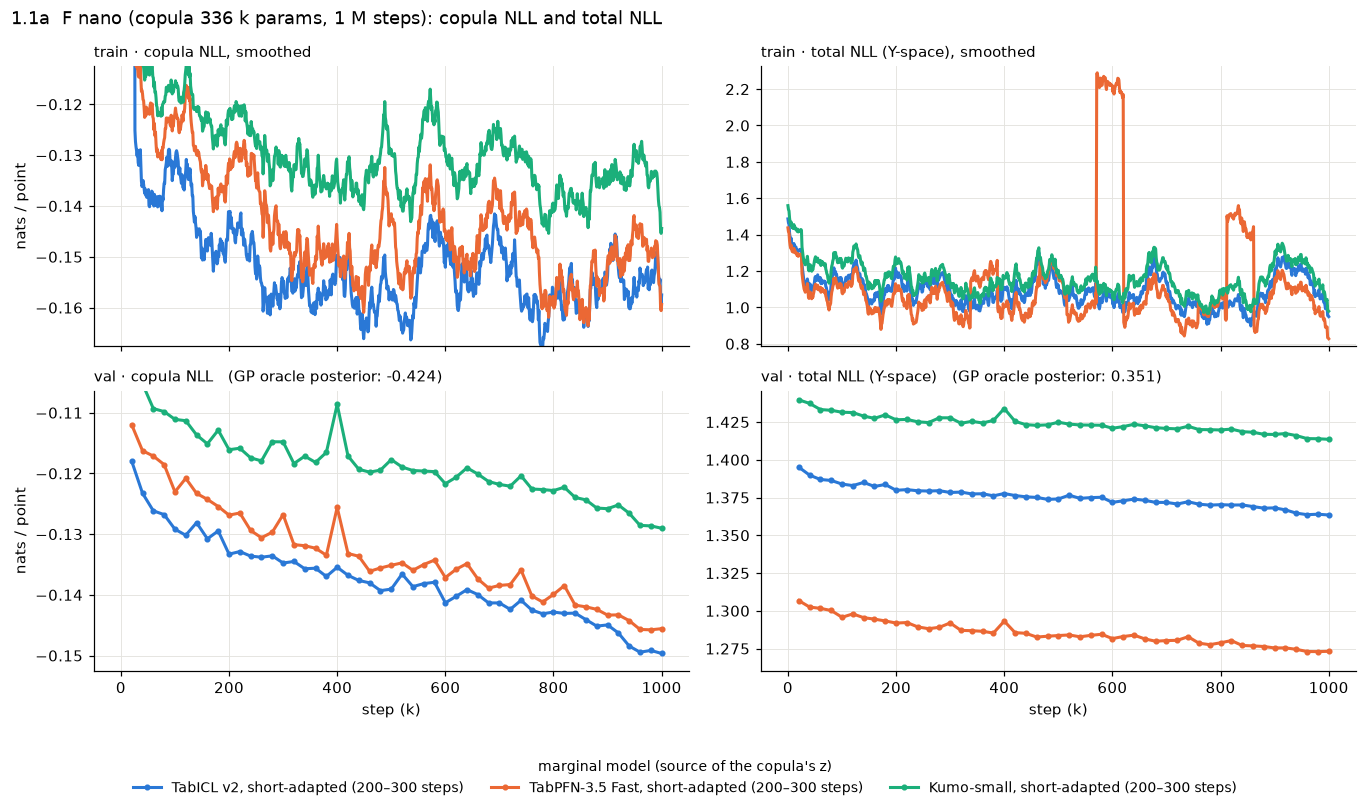

In [5]:
fig = plot_nll_curves(
    E1["F nano"],
    "1.1a  F nano (copula 336 k params, 1 M steps): copula NLL and total NLL",
    names={be: run_label(be, "A") for be in COLORS},
)

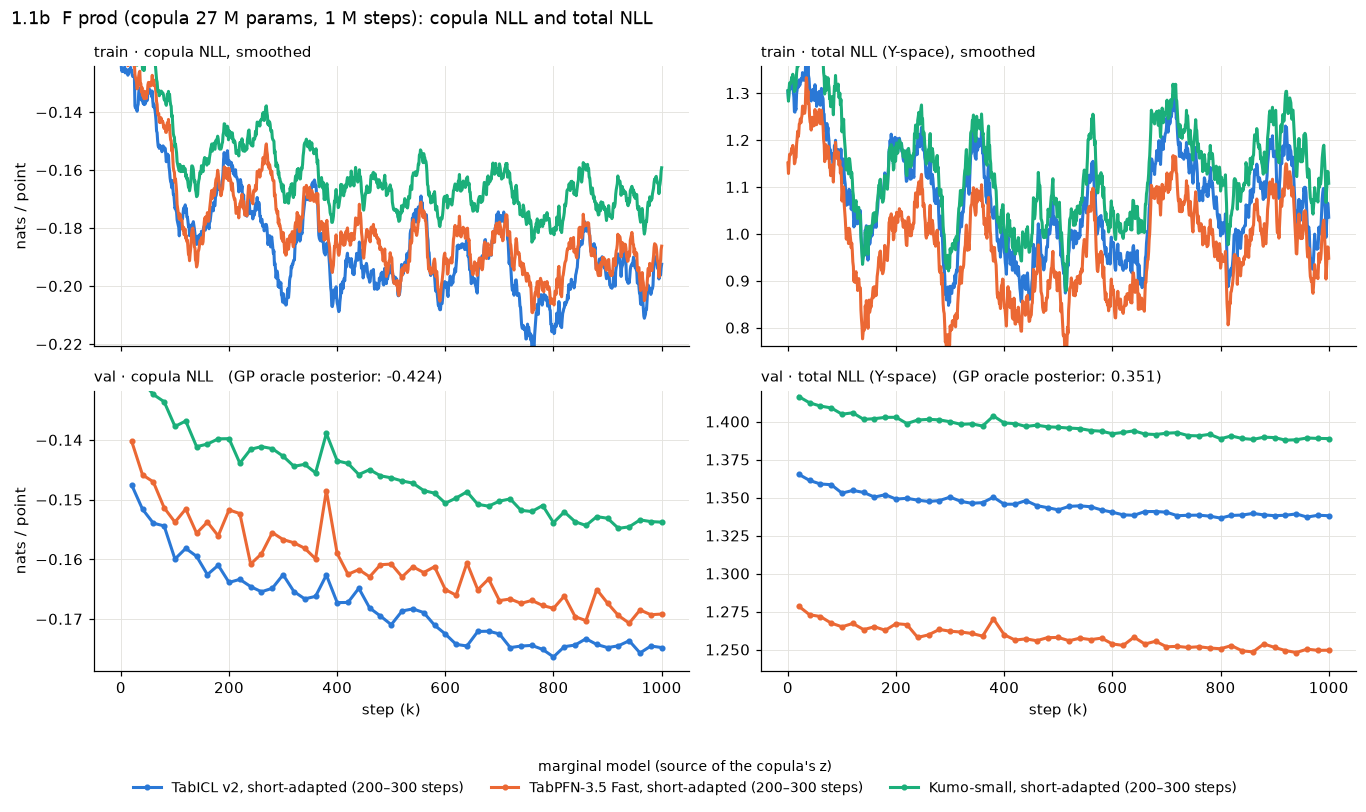

In [6]:
fig = plot_nll_curves(
    E1["F prod"],
    "1.1b  F prod (copula 27 M params, 1 M steps): copula NLL and total NLL",
    names={be: run_label(be, "A") for be in COLORS},
)

In [7]:
# Last validation point of every group (nats/point; lower is better).
FINAL1 = pd.concat({g: final_val(r) for g, r in E1.items()}, names=["group"])
FINAL1[["step", "val copula", "val marginal", "val total", "gap to oracle"]]

step  val copula  val marginal  val total  gap to oracle
group  run                                                                
F nano TabICL  1000000     -0.1497        1.5131     1.3634         1.0129
       TabPFN  1000000     -0.1456        1.4188     1.2732         0.9226
       Kumo    1000000     -0.1290        1.5426     1.4135         1.0630
F prod TabICL  1000000     -0.1748        1.5129     1.3381         0.9875
       TabPFN  1000000     -0.1692        1.4187     1.2496         0.8990
       Kumo    1000000     -0.1538        1.5426     1.3888         1.0382
R nano TabICL   100000     -0.1388        1.5131     1.3743         1.0238
       TabPFN   100000     -0.1321        1.4187     1.2866         0.9361
       Kumo     100000     -0.1213        1.5426     1.4213         1.0708
R prod TabICL   100000     -0.1672        1.5131     1.3459         0.9954
       TabPFN   100000     -0.1591        1.4188     1.2597         0.9091
       Kumo     100000     -0.1441        1.5426     1.3985         1.0479
S prod TabICL   100000     -0.1427        1.5132     1.3705         1.0199
       TabPFN   100000     -0.1428        1.4187     1.2760         0.9255
       Kumo     100000     -0.1261        1.5410     1.4149         1.0644

### 1.2 Why the marginals need finetuning

The copula's total NLL inherits the marginal's NLL, so a weaker marginal caps the whole model. TabICL went through a
long ERA5 Phase-A finetune (`marginal_finetune_era5_run1`, step 177 600). TabPFN and Kumo only had 200–300 steps.
Both were then finetuned **the same way** as TabICL (ERA5 + synthetic GP mix, pinball loss, LoRA rank 8 on all
layers, tier 3, best checkpoint by `val_marginal/mean_nll`):

| Backend | Finetune run | Steps run | Checkpoint used |
|---|---|---|---|
| TabICL | `aldwo2by` | 200 k | `marginal_finetune_era5_run1/step_0177600` |
| TabPFN | `bividp6n` | 40 k | `marginal_finetune_era5_tabpfn35_fast/step_0027500` |
| Kumo | `5elxvkpq` | 150 k | `marginal_finetune_era5_kumo_small/step_0114500` |

The comparison below scores each marginal before and after finetuning on the same validation sets
(`finetune_marginal` with 0 steps). It covers the synthetic GP episodes and five ERA5 regions.

In [8]:
# Pretrained vs finetuned marginal, scored by finetune_marginal with steps=0. Two evaluation batches (A, B).
CMP = {
    "A": {
        ("TabICL", "pretrained"): "u9xpvppr",
        ("TabICL", "finetuned"): "9169fs46",
        ("TabPFN", "pretrained"): "wngy0kjm",
        ("TabPFN", "finetuned"): "dte2hdb2",
        ("Kumo", "pretrained"): "wqfppbzz",
        ("Kumo", "finetuned"): "5d9u3hb9",
    },
    "B": {
        ("TabICL", "pretrained"): "nguz24z3",
        ("TabICL", "finetuned"): "pygs3zga",
        ("TabPFN", "pretrained"): "v7xrmxss",
        ("TabPFN", "finetuned"): "5qipt0sr",
        ("Kumo", "pretrained"): "kkn659vz",
        ("Kumo", "finetuned"): "ozzwijc1",
    },
}
MARG_METRICS = {
    "val_marginal/gp/nll": "GP NLL",
    "val_marginal/mean_nll": "ERA5 NLL",
    "val_marginal/mean_crps": "ERA5 CRPS",
    "val_marginal/mean_ks": "ERA5 PIT KS",
}
MARG = pd.DataFrame(
    [
        {
            "batch": b,
            "backend": be,
            "marginal": st,
            **{v: run_info(rid, MARGINAL)["summary"].get(k) for k, v in MARG_METRICS.items()},
        }
        for b, runs in CMP.items()
        for (be, st), rid in runs.items()
    ]
).set_index(["batch", "backend", "marginal"])
MARG

GP NLL  ERA5 NLL  ERA5 CRPS  ERA5 PIT KS
batch backend marginal                                            
A     TabICL  pretrained  1.3969    1.9114     1.0357       0.1508
              finetuned   1.1684    1.5812     0.9096       0.1228
      TabPFN  pretrained  1.2178    1.8263     1.0294       0.1321
              finetuned   1.1367    1.5954     0.9150       0.1283
      Kumo    pretrained  1.3729    2.1035     1.0301       0.1450
              finetuned   1.2239    1.6497     0.8169       0.1246
B     TabICL  pretrained  0.9153    2.0150     1.0525       0.1268
              finetuned   0.7876    1.6077     0.9026       0.0690
      TabPFN  pretrained  0.8046    1.8567     1.0420       0.0843
              finetuned   0.7150    1.6333     0.9282       0.0742
      Kumo    pretrained  0.9458    2.0544     1.0069       0.0872
              finetuned   0.8221    1.7223     0.8334       0.0576

In [9]:
# What differs between the two evaluation batches (pretrained TabICL in each)?
ca, cb = (
    run_info(CMP["A"][("TabICL", "pretrained")], MARGINAL)["config"],
    run_info(CMP["B"][("TabICL", "pretrained")], MARGINAL)["config"],
)
diff = {
    k: (str(ca.get(k))[:90], str(cb.get(k))[:90])
    for k in sorted(set(ca) | set(cb))
    if str(ca.get(k)) != str(cb.get(k)) and not k.startswith(("_wandb", "wandb."))
}
pd.DataFrame(diff, index=["batch A", "batch B"]).T if diff else print(
    "same config: the batches differ only by run time"
)

,batch A,batch B
validation.era5_n_days_probe,3,24
validation.gp_n_batches,8,64


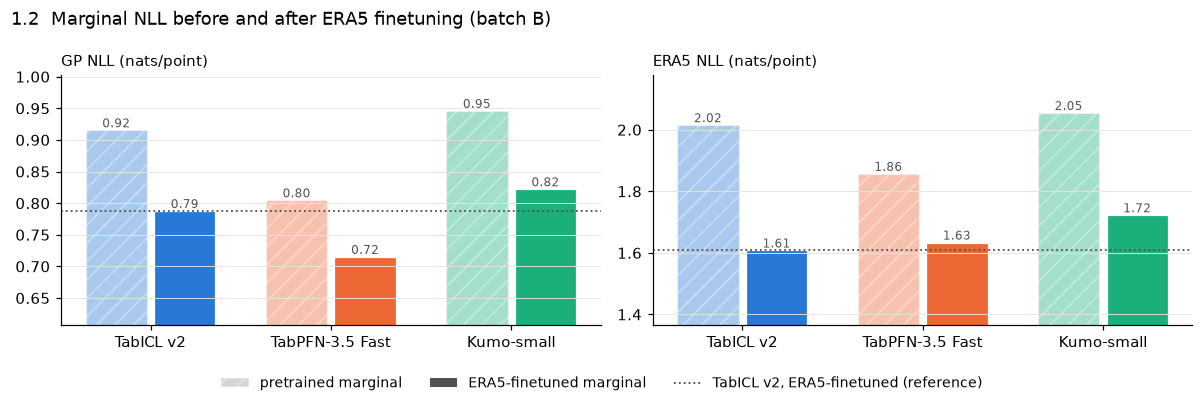

In [10]:
# Batch B: the finetuned TabICL (dotted line) is the reference the other marginals have to reach.
B = MARG.loc["B"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, metric in zip(axes, ["GP NLL", "ERA5 NLL"]):
    for i, be in enumerate(COLORS):
        for j, st in enumerate(["pretrained", "finetuned"]):
            v = B.loc[(be, st), metric]
            ax.bar(
                i + (j - 0.5) * 0.38,
                v,
                width=0.34,
                color=COLORS[be],
                alpha=0.4 if st == "pretrained" else 1.0,
                hatch="//" if st == "pretrained" else None,
                edgecolor="white",
                linewidth=0.8,
            )
            ax.text(i + (j - 0.5) * 0.38, v, f"{v:.2f}", ha="center", va="bottom", fontsize=8, color="#52514e")
    ax.axhline(B.loc[("TabICL", "finetuned"), metric], color="#52514e", ls=":", lw=1.2)
    ax.set_xticks(range(len(COLORS)), [MARGINAL_NAME[b] for b in COLORS])
    lo = B[metric].min()
    ax.set_ylim(lo * 0.85, B[metric].max() * 1.06)
    ax.set_title(f"{metric} (nats/point)", loc="left", fontsize=10)
    ax.grid(axis="x", visible=False)
from matplotlib.patches import Patch  # noqa: E402

fig.legend(
    handles=[
        Patch(facecolor="#9a9893", alpha=0.4, hatch="//", edgecolor="white", label="pretrained marginal"),
        Patch(facecolor="#52514e", label="ERA5-finetuned marginal"),
        Line2D([], [], color="#52514e", ls=":", lw=1.2, label="TabICL v2, ERA5-finetuned (reference)"),
    ],
    loc="lower center",
    ncol=3,
    fontsize=9,
)
fig.suptitle("1.2  Marginal NLL before and after ERA5 finetuning (batch B)", x=0.01, ha="left", fontsize=12)
fig.tight_layout(rect=(0, 0.08, 1, 1))

### 1.3 Marginal finetuning curves

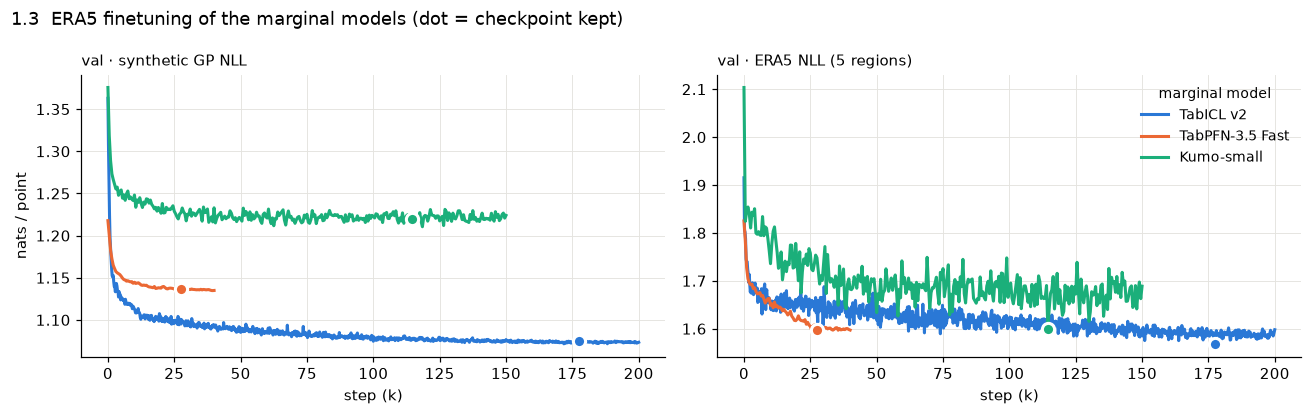

In [11]:
FT_MARG = {"TabICL": ("aldwo2by", 177_600), "TabPFN": ("bividp6n", 27_500), "Kumo": ("5elxvkpq", 114_500)}
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharex=True)
for be, (rid, kept) in FT_MARG.items():
    for ax, key in zip(axes, ["val_marginal/gp/nll", "val_marginal/mean_nll"]):
        h = history(rid, [key], MARGINAL).dropna()
        if not len(h):
            print(f"{be} ({rid}): {key} not logged")
            continue
        ax.plot(h.step / 1e3, h[key], color=COLORS[be], label=MARGINAL_NAME[be])
        k = h.iloc[(h.step - kept).abs().argmin()]
        ax.plot(k.step / 1e3, k[key], "o", ms=8, color=COLORS[be], mec="white", mew=2)
for ax, t in zip(axes, ["val · synthetic GP NLL", "val · ERA5 NLL (5 regions)"]):
    ax.set_title(t, loc="left", fontsize=10)
    ax.set_xlabel("step (k)")
axes[0].set_ylabel("nats / point")
axes[1].legend(fontsize=9, title="marginal model", title_fontsize=9)
fig.suptitle("1.3  ERA5 finetuning of the marginal models (dot = checkpoint kept)", x=0.01, ha="left", fontsize=12)
fig.tight_layout()

### 1.4 Copula on the finetuned marginals (`FT_nano_*`, 2026-11-09 → 11-10, finished)

Same nano recipe as `R nano` (100 k steps, val every 5 k). The only difference is the marginal checkpoints
(`data.z_train_marginal_ckpt`, `tabicl.pit_ckpt`), which are the finetuned ones from §1.3. They are drawn against
the **complete** training of the short-adapted runs `F nano` (1 M steps, dashed) on a log step axis, so the FT
curve can be read against the whole A trajectory. All runs share one validation set (fixed $P = 32$, $N = 256$).

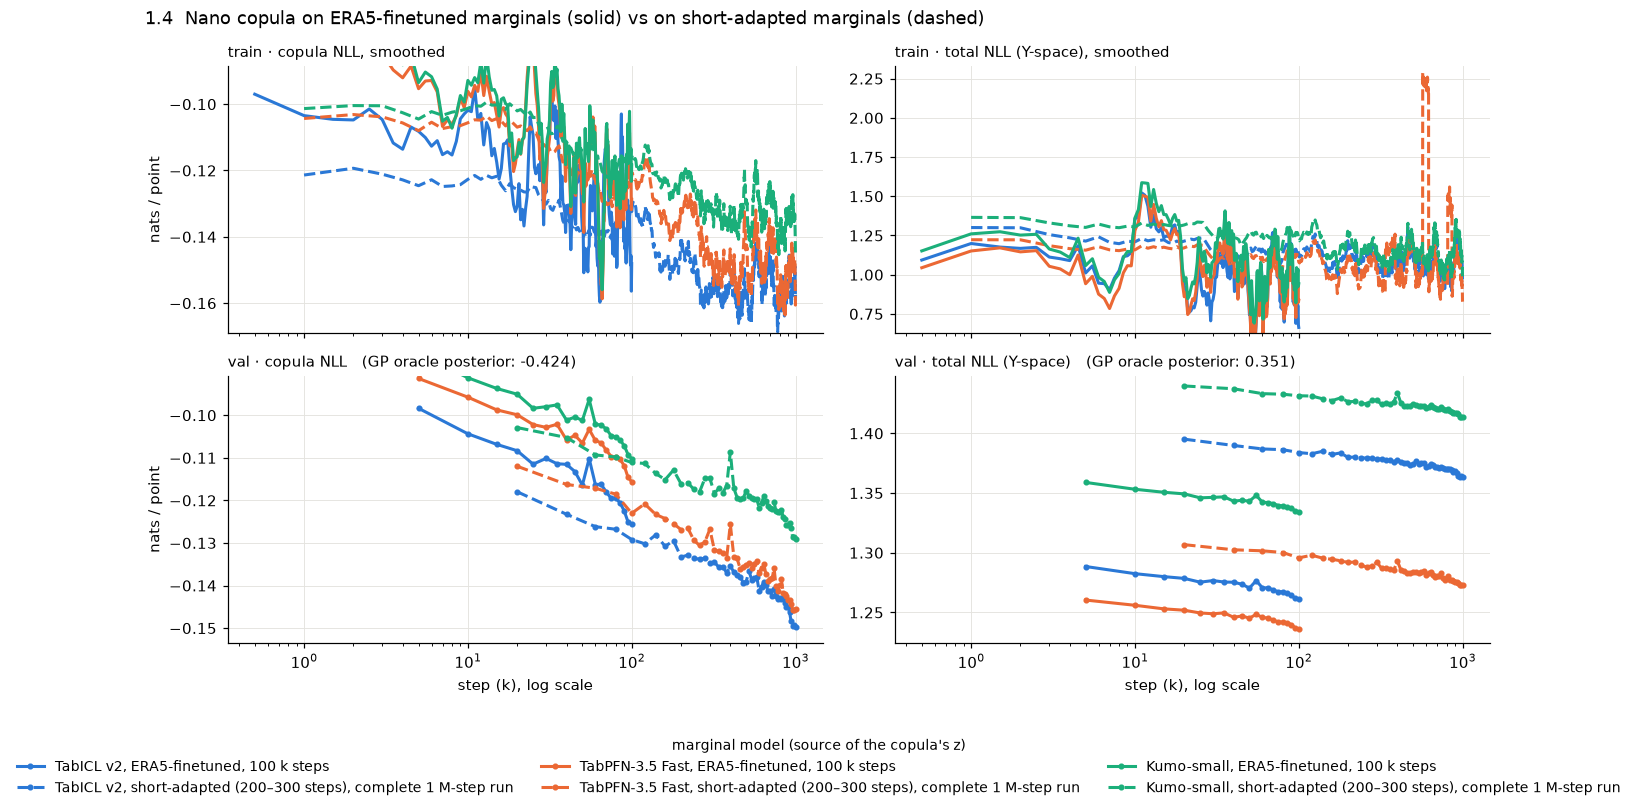

In [12]:
# Interleaved by backend, so each legend column is one marginal model (finetuned on top, short-adapted below).
FT_COPULA = {
    k: v
    for be in COLORS
    for k, v in [
        (f"{be} FT", {"TabICL": "a2bhgm9x", "TabPFN": "s7e2wxv7", "Kumo": "bes8xbar"}[be]),
        (f"{be} A", E1["F nano"][be]),
    ]
}
NAMES_14 = {
    f"{be} {rc}": run_label(be, rc) + (", 100 k steps" if rc == "FT" else ", complete 1 M-step run")
    for be in COLORS
    for rc in ("FT", "A")
}
fig = plot_nll_curves(
    FT_COPULA,
    "1.4  Nano copula on ERA5-finetuned marginals (solid) vs on short-adapted marginals (dashed)",
    dashed=tuple(f"{be} A" for be in COLORS),
    logx=True,
    names=NAMES_14,
    ncol=3,
)

In [13]:
# Last validation step, from the wandb-results report. R nano = A at 100 k steps (same schedule as FT).
FIX = wandb_report("fixed_size_ft", "ids=[" + ",".join([*FT_COPULA.values(), *E1["R nano"].values()]) + "]")
report_frame(FIX)[
    [
        "state",
        "step",
        "marginal (= indep.)",
        "copula",
        "full",
        "excess vs oracle",
        "copula exact z",
        "best full",
        "best @",
    ]
]

,state,step,marginal (= indep.),copula,full,excess vs oracle,copula exact z,best full,best @
run,,,,,,,,,
FT_nano_tabpfn,finished,100000,1.3518,-0.1156,1.2361,0.8856,-0.0343,1.2361,100000
FT_nano_tabicl,finished,100000,1.3869,-0.1255,1.2613,0.9108,-0.0286,1.2613,100000
F_nano_tabpfn_A,finished,1000000,1.4188,-0.1456,1.2732,0.9226,-0.0194,1.2730,980000
R_nano_tabpfn_A,finished,100000,1.4187,-0.1321,1.2866,0.9361,-0.0223,1.2866,100000
FT_nano_kumo,finished,100000,1.4444,-0.1102,1.3341,0.9836,-0.0323,1.3341,100000
F_nano_tabicl_A,finished,1000000,1.5131,-0.1497,1.3634,1.0129,-0.0411,1.3634,1000000
R_nano_tabicl_A,finished,100000,1.5131,-0.1388,1.3743,1.0238,-0.0454,1.3743,100000
F_nano_kumo_A,finished,1000000,1.5426,-0.1290,1.4135,1.0630,-0.0364,1.4135,1000000
R_nano_kumo_A,finished,100000,1.5426,-0.1213,1.4213,1.0708,-0.0417,1.4213,100000


In [14]:
# FT vs R nano (A marginal, same schedule) at the latest validation step both reached: same number of copula steps.
def matched_step(pairs: dict[str, tuple[str, str]]) -> pd.DataFrame:
    rows = []
    for be, (ft, a) in pairs.items():
        hf, ha = (history(r, VAL_KEYS).dropna().groupby("step").last() for r in (ft, a))
        common = hf.index.intersection(ha.index)
        if len(common):
            s = common.max()
            rows.append(
                {
                    "backend": be,
                    "step": s,
                    "Δ copula (FT − A)": hf.loc[s, VAL_KEYS[0]] - ha.loc[s, VAL_KEYS[0]],
                    "Δ total (FT − A)": hf.loc[s, VAL_KEYS[1]] - ha.loc[s, VAL_KEYS[1]],
                    "FT total": hf.loc[s, VAL_KEYS[1]],
                    "A total": ha.loc[s, VAL_KEYS[1]],
                }
            )
    return pd.DataFrame(rows).set_index("backend")


matched_step({be: (FT_COPULA[f"{be} FT"], E1["R nano"][be]) for be in COLORS})

,step,Δ copula (FT − A),Δ total (FT − A),FT total,A total
backend,,,,,
TabICL,100000,0.0132,-0.1130,1.2613,1.3743
TabPFN,100000,0.0165,-0.0505,1.2361,1.2866
Kumo,100000,0.0111,-0.0871,1.3341,1.4213


**Conclusion (2026-11-10; validation NLL, nats/point).**

- **With short adaptation only (§1.1), the copula term barely depends on the backend; the marginal sets the total.**
  F nano at 1 M steps: copula $-0.150$ (TabICL), $-0.146$ (TabPFN), $-0.129$ (Kumo); total $1.363$, $1.273$, $1.414$.
  Prod lowers the copula term by $\approx 0.025$ for every backend. The gap to the GP oracle ($\approx 0.9$–$1.0$) is
  mostly marginal: oracle marginal $= 0.351 - (-0.424) = 0.775$ vs $1.42$–$1.54$ here, against $0.28$ on the copula side.
- **Pretrained TabPFN and Kumo are clearly worse than finetuned TabICL on real data (§1.2, batch B).** ERA5 NLL:
  $1.857$ (TabPFN) and $2.054$ (Kumo) vs $1.608$ (finetuned TabICL). **So they get the same ERA5 finetuning.** After
  it: TabPFN $1.633$ ($+0.025$ vs TabICL), Kumo $1.722$ ($+0.115$). On synthetic GP, finetuned TabPFN is best
  ($0.715$ vs $0.788$). Kumo plateaus early in finetuning (§1.3).
- **Copula on finetuned marginals (§1.4, final, 100 k steps).** Against `R nano` at the same step (100 k):

  | Backend | Δ total (FT − A) | Δ marginal | Δ copula (live $z$) | copula exact $z$: FT / A |
  |---|---|---|---|---|
  | TabICL | $-0.113$ | $-0.126$ | $+0.013$ | $-0.029$ / $-0.045$ |
  | TabPFN | $-0.051$ | $-0.067$ | $+0.017$ | $-0.034$ / $-0.022$ |
  | Kumo | $-0.087$ | $-0.098$ | $+0.011$ | $-0.032$ / $-0.042$ |

  The total gain is the marginal's. FT at 100 k also beats the complete 1 M-step A runs on total ($1.261$ vs $1.363$,
  $1.236$ vs $1.273$, $1.334$ vs $1.414$). The live-$z$ copula term is $0.01$–$0.02$ worse with FT: a better marginal
  leaves less dependence in its PIT residuals for the copula to absorb. On exact $z$ (GP correlation only) the
  comparison is mixed (finetuned TabPFN-3.5 Fast better, finetuned TabICL v2 and Kumo-small worse), so FT does not degrade the copula itself.
  **Best model: TabPFN-3.5 Fast (ERA5-finetuned) + copula, val total $1.236$** (oracle $0.351$; excess $0.886$ = marginal $0.577$ + copula $0.309$).

---
## 2. New real-data regression datasets

**Question.** Does the copula, trained only on synthetic GP episodes, lower the total NLL on real regression data?
The references are the independence row (same marginal, no copula) and the autoregressive row.

**Setup (branch `real-data-datasets`, 2026-11-04).** `eval_checkpoint` with `real.dataset=<name>`, nano
checkpoint pair (`REAL_CKPT_TAG=nano`). The per-episode dumps are in `results/real/<dataset>/<cell>_nano_o<offset>.json`.

| Dataset | What it is | Cells |
|---|---|---|
| `kaust` | KAUST 2022 competition fields, (x, y) features, P = 128, N = 64. `*_2` = nonstationary Matérn GP (main); `*_1` = mean + iid noise (negative control: the copula must not hurt) | {1a,1b}_{1,2} × {random, block}; P sweep on 1a_2 |
| `sdwpf` | SDWPF wind farm (KDD Cup 2022), day-block folds | f0 × {random, block}; P ∈ {16, 64} |
| `emnist` | one test image per episode, pixel value on (row, col) | P ∈ {50, 200} × {random, block} |
| `california` | California Housing, top-code dropped; f0 = 8 features, f1 = without lat/lon | {f0, f1} × {random, block}; P sweep on f0 |
| `meuse` | Meuse log(zinc), repeated 3-fold (folds overlap → mean ± sd, no CI) | f0, f1 |
| `ctr23` | OpenML-CTR23 regression suite, 24 kept datasets (11/35 dropped by the atom rule) | per dataset × {dyadic_knn, random} |

The full analysis is in `notebooks/real_results.ipynb`: calibration gate, Wilcoxon across CTR23, P sweep.
Here only the headline is shown.

In [15]:
RESULTS = ROOT / "results/real"
TAG = "nano"
EXPECTED = {"meuse": 201, "ctr23": 100}  # episodes per cell; 400 otherwise
N_BOOT = 1000


@functools.lru_cache(maxsize=None)
def n_episodes(pattern: str) -> int:
    return sum(len(json.loads(Path(f).read_text())["episodes"]) for f in glob.glob(pattern))


pat = re.compile(rf"^(?P<cell>.+)_{TAG}_o(?P<off>\d+)\.json$")
rows = [
    {"dataset": f.parent.name, "cell": m["cell"]}
    for f in sorted(RESULTS.glob(f"*/*_{TAG}_o*.json"))
    if (m := pat.match(f.name))
]
INV = pd.DataFrame(rows).groupby(["dataset", "cell"]).size().rename("shards").reset_index()
INV["glob"] = [str(RESULTS / d / f"{c}_{TAG}_o*[0-9].json") for d, c in zip(INV.dataset, INV.cell)]
INV["episodes"] = [n_episodes(g) for g in INV.glob]
INV["complete"] = INV.episodes >= INV.dataset.map(EXPECTED).fillna(400)
INV.groupby("dataset").agg(cells=("cell", "size"), complete=("complete", "sum"), episodes=("episodes", "sum"))

,cells,complete,episodes
dataset,,,
california,6,6,2400
ctr23,48,48,4800
emnist,4,4,1600
kaust,10,10,4000
meuse,2,2,402
sdwpf,4,3,1599


In [16]:
# Copula minus each reference, total NLL, complete cells only (95 % cluster-bootstrap CI).
def contrasts(row) -> list[dict]:
    res = within_run_deltas(PairedCompareSpec(a=row.glob, n_boot=N_BOOT))
    return [
        {"dataset": row.dataset, "cell": row.cell, "contrast": c.removeprefix("copula - "), **s}
        for c, terms in res.items()
        for t, s in terms.items()
        if t == "total" and s.get("n")
    ]


DONE = INV[INV.complete]
W2 = pd.DataFrame([r for row in DONE.itertuples() for r in contrasts(row)])


def verdict(r) -> str:
    if not np.isfinite(r.lo):
        return "no CI"
    return "better" if r.hi < 0 else ("worse" if r.lo > 0 else "n.s.")


W2["verdict"] = [verdict(r) for r in W2.itertuples()]
pd.crosstab([W2.dataset], [W2.contrast, W2.verdict])

/srv/storage/thoth1@storage4.grenoble.grid5000.fr/trmartin/copula-inter/.venv/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/srv/storage/thoth1@storage4.grenoble.grid5000.fr/trmartin/copula-inter/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


contrast   autoregressive                  independence                 
verdict            better n.s. no CI worse       better n.s. no CI worse
dataset                                                                 
california              4    0     0     2            5    1     0     0
ctr23                   5   14     0    29           42    5     0     1
emnist                  1    0     0     3            4    0     0     0
kaust                   2    1     0     7           10    0     0     0
meuse                   0    0     2     0            0    0     2     0
sdwpf                   2    1     0     0            3    0     0     0

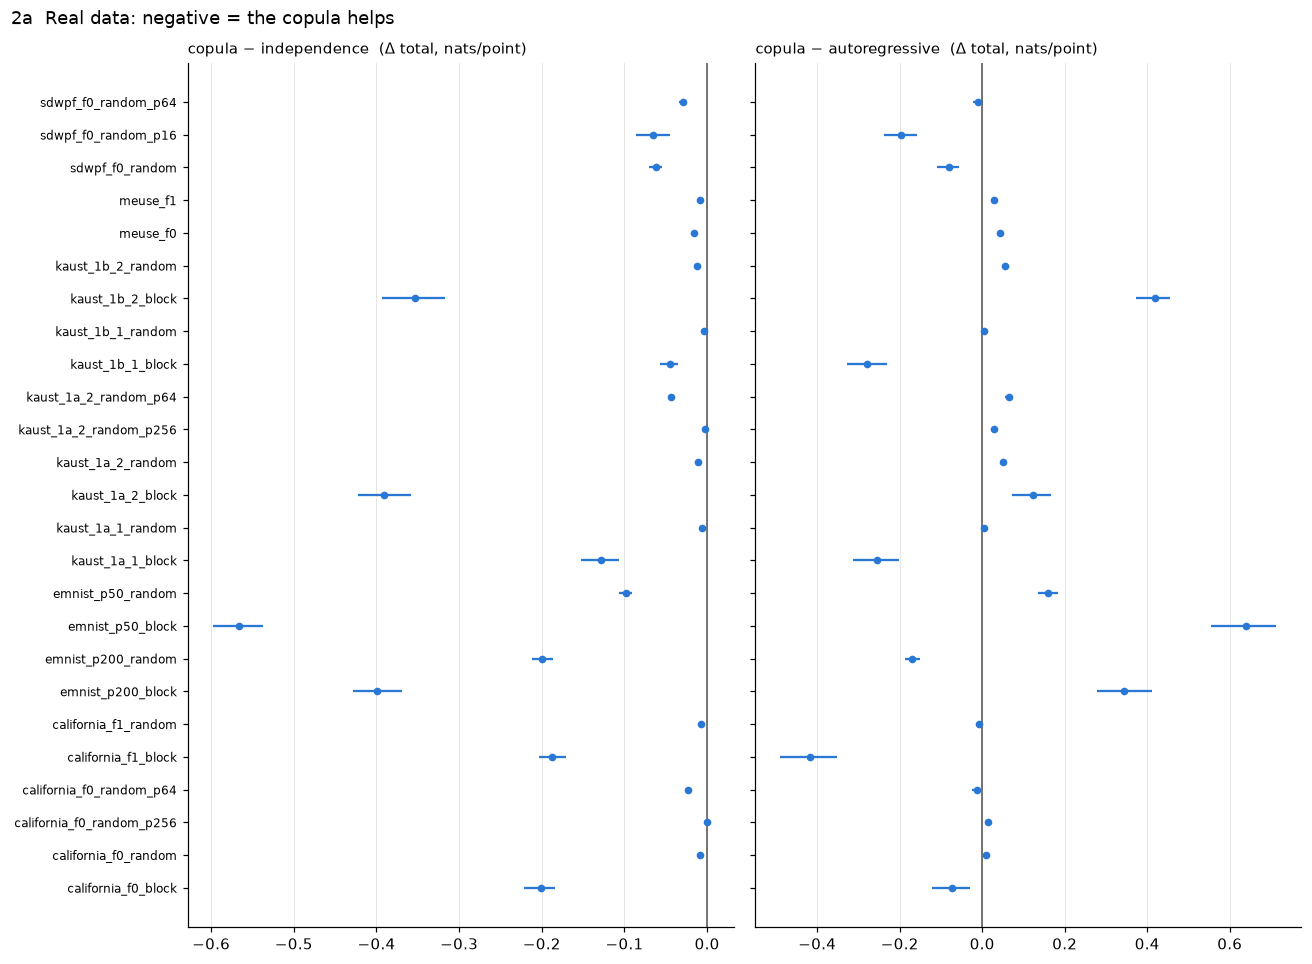

In [17]:
# Forest plot, non-CTR23 cells: copula - independence and copula - autoregressive (total, per point).
H = W2[W2.dataset != "ctr23"]
cells = list(dict.fromkeys(H.cell))
refs = [c for c in ["independence", "autoregressive"] if c in set(H.contrast)]
fig, axes = plt.subplots(1, len(refs), figsize=(6 * len(refs), 0.3 * len(cells) + 1.4), sharey=True, squeeze=False)
for ax, ref in zip(axes[0], refs):
    d = H[H.contrast == ref].set_index("cell").reindex(cells)
    y = np.arange(len(cells))
    err = np.vstack([d["mean"] - d.lo, d.hi - d["mean"]])
    ax.errorbar(
        d["mean"],
        y,
        xerr=np.where(np.isfinite(err), err, 0),
        fmt="o",
        ms=4,
        color=COLORS["TabICL"],
        ecolor=COLORS["TabICL"],
        elinewidth=1.5,
        capsize=0,
    )
    ax.axvline(0, color="#52514e", lw=1)
    ax.set_title(f"copula − {ref}  (Δ total, nats/point)", loc="left", fontsize=10)
    ax.set_yticks(y, cells, fontsize=8)
    ax.invert_yaxis()
    ax.grid(axis="y", visible=False)
fig.suptitle("2a  Real data: negative = the copula helps", x=0.01, ha="left", fontsize=12)
fig.tight_layout()

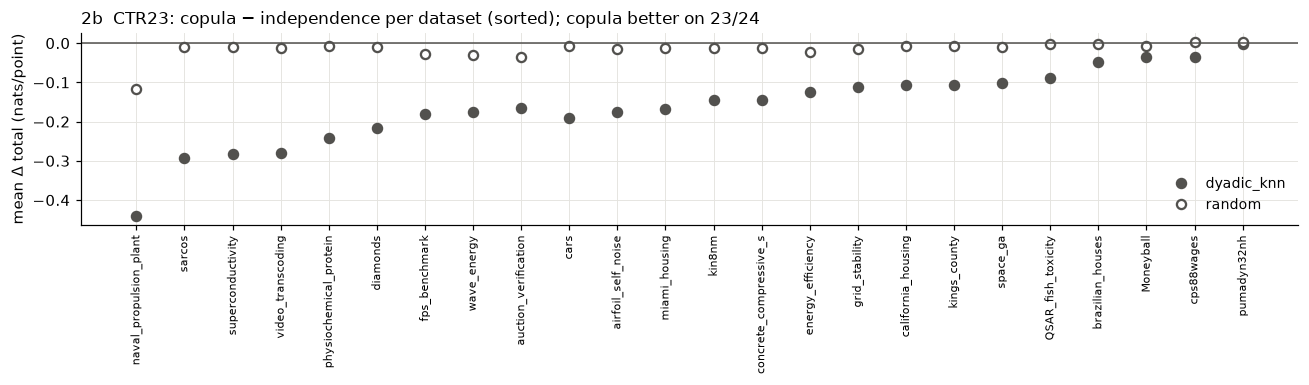

In [18]:
# CTR23: per-dataset mean Δ (copula - independence, total), one dot per dataset and mask.
C = W2[(W2.dataset == "ctr23") & (W2.contrast == "independence")].copy()
if C.empty:
    print("no complete CTR23 cell yet")
else:
    C["mask"] = C.cell.str.extract(r"^ctr23_\d+_(.+)$")[0]
    C["data_id"] = C.cell.str.extract(r"^ctr23_(\d+)_")[0]
    order = C.groupby("data_id")["mean"].mean().sort_values().index
    fig, ax = plt.subplots(figsize=(12, 3.6))
    for k, (mask, g) in enumerate(C.groupby("mask")):
        g = g.set_index("data_id").reindex(order)
        ax.plot(
            range(len(order)),
            g["mean"],
            "o",
            ms=6,
            color="#52514e",
            mfc="#52514e" if k == 0 else "white",
            mew=1.5,
            label=mask,
        )
    ax.axhline(0, color="#52514e", lw=1)
    _audit = RESULTS / "audit/ctr23_suite.json"
    names = (
        {k: v["name"] for k, v in json.loads(_audit.read_text())["suite"]["datasets"].items()}
        if _audit.is_file()
        else {}
    )
    ax.set_xticks(range(len(order)), [names.get(i, i)[:22] for i in order], rotation=90, fontsize=7)
    ax.set_ylabel("mean Δ total (nats/point)")
    ax.legend(fontsize=9)
    better = (C.groupby("data_id")["mean"].mean() < 0).sum()
    ax.set_title(
        f"2b  CTR23: copula − independence per dataset (sorted); copula better on {better}/{len(order)}",
        loc="left",
        fontsize=11,
    )
    fig.tight_layout()

### 2c CTR23 on the full datasets: copula vs independence

`eval.runners.ctr23_full_eval` (`scripts/ctr23_full.sh <data_id> <method>`): the task's official 10-fold CV, the
whole training fold as context and the whole test fold as queries. One JSON per dataset and method in
`results/real/ctr23_full/<data_id>_<method>.json`. Independence is the marginal alone, so per point

$$\Delta_T = \text{NLL}_\text{total}(\text{copula}) - \text{NLL}_\text{total}(\text{independence}) = \text{copula NLL over } T,$$

for $T$ = the whole test fold (`whole`) or its partition into 64-row chunks (`random`, `dyadic_knn`). Per dataset:
mean over folds; across datasets: the Wilcoxon signed-rank test (the dataset is the unit). Negative = copula better.

In [19]:
from eval.runners.ctr23_full_eval import compare_methods, compare_with_independence, method_scores

FULL = RESULTS / "ctr23_full"
# Method label -> file suffix. Match the suffix exactly: "*_nano.json" would also catch "*_kumo_ft_nano.json".
# The name says which marginal model, in which state, and whether a copula is on top.
METHODS = {
    "TabICL v2 (ERA5-finetuned) + copula": "nano",
    "Kumo-small (ERA5-finetuned) + copula": "kumo_ft_nano",
    "TabPFN-3.5 Fast (ERA5-finetuned) + copula": "tabpfn_ft_nano",
    "TabICL v2 (pretrained), no copula": "tabicl_base",
    "TabPFN-3.5 Fast (pretrained), no copula": "tabpfn35_fast",
    "Kumo-small (pretrained), no copula": "kumo_small",
}


def load_full(method: str) -> list[dict]:
    pat = re.compile(rf"^\d+_{method}\.json$")
    return [json.loads(f.read_text()) for f in sorted(FULL.glob("*.json")) if pat.match(f.name)]


def n_complete(blobs: list[dict]) -> int:
    return sum(len(b["folds"]) == b["dataset"]["n_folds"] and not b.get("failed") for b in blobs)


BLOBS = {m: load_full(t) for m, t in METHODS.items()}
pd.DataFrame(
    {
        "files": {m: len(b) for m, b in BLOBS.items()},
        "complete (10/10 folds)": {m: n_complete(b) for m, b in BLOBS.items()},
        "failed": {m: sum(bool(x.get("failed")) for x in b) for m, b in BLOBS.items()},
    }
)

,files,complete (10/10 folds),failed
TabICL v2 (ERA5-finetuned) + copula,24,24,0
Kumo-small (ERA5-finetuned) + copula,24,24,0
TabPFN-3.5 Fast (ERA5-finetuned) + copula,24,24,0
"TabICL v2 (pretrained), no copula",24,24,0
"TabPFN-3.5 Fast (pretrained), no copula",24,24,0
"Kumo-small (pretrained), no copula",24,24,0


In [20]:
# TabICL v2 (ERA5-finetuned) + copula against the same marginal alone (independence), across the complete datasets.
CMPF = compare_with_independence(BLOBS["TabICL v2 (ERA5-finetuned) + copula"])
cols = ["n_datasets", "mean_delta", "median_delta", "copula_wins", "independence_wins", "p_value"]
pd.DataFrame(CMPF["summary"]).T.reindex(columns=cols)

,n_datasets,mean_delta,median_delta,copula_wins,independence_wins,p_value
whole,24.0,-0.0697,-0.0094,16.0,8.0,0.0315
random,24.0,-0.0274,0.0017,11.0,13.0,0.7683
dyadic_knn,24.0,-0.0627,-0.0038,15.0,9.0,0.1208


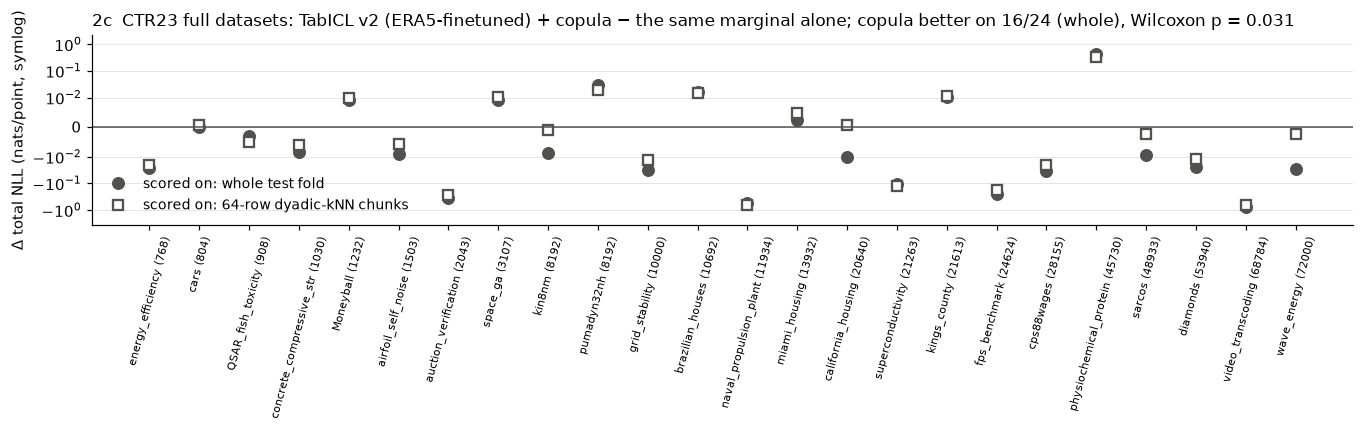

In [21]:
# Per dataset Δ (copula - independence), sorted by dataset size: does the gain hold as P grows?
FD = pd.DataFrame(CMPF["per_dataset"]).set_index("name").sort_values("n_rows")
fig, ax = plt.subplots(figsize=(12.5, 4))
x = np.arange(len(FD))
for t, mk, fill in [("whole", "o", True), ("dyadic_knn", "s", False)]:
    ax.plot(
        x,
        FD[f"delta_{t}"],
        mk,
        ms=7,
        color="#52514e",
        mfc="#52514e" if fill else "white",
        mew=1.5,
        ls="none",
        label=f"scored on: {'whole test fold' if t == 'whole' else '64-row dyadic-kNN chunks'}",
    )
ax.axhline(0, color="#52514e", lw=1)
ax.set_yscale("symlog", linthresh=0.01)
ax.margins(y=0.12)
ax.set_xticks(x, [f"{n[:24]} ({r})" for n, r in zip(FD.index, FD.n_rows)], rotation=75, fontsize=7)
ax.set_ylabel("Δ total NLL (nats/point, symlog)")
w = CMPF["summary"]["whole"]
ax.set_title(
    f"2c  CTR23 full datasets: TabICL v2 (ERA5-finetuned) + copula − the same marginal alone; copula better on {w['copula_wins']}/{w['n_datasets']}"
    f" (whole), Wilcoxon p = {w.get('p_value', float('nan')):.2g}",
    loc="left",
    fontsize=11,
)
ax.legend(fontsize=9, loc="lower left")
ax.grid(axis="x", visible=False)
fig.tight_layout()

### 2d CTR23 full datasets: ranking against the other tabular foundation models

Same folds and contexts for every method. A copula row is scored on its joint NLL over the whole test fold; a
marginal row (independence) on its marginal NLL. `TabICL v2 (ERA5-finetuned), no copula` is the marginal half of the TabICL copula run.
Ranks are per dataset (1 = best), over the datasets **every ranked method** completed; methods with fewer than
`MIN_DATASETS` complete datasets are still running and are left out (listed).

In [22]:
MIN_DATASETS = 15
SCORES = {}
for m, blobs in BLOBS.items():
    if n_complete(blobs) < MIN_DATASETS:
        print(f"pending: {m} ({n_complete(blobs)}/24 complete)")
        continue
    if m.endswith(" + copula"):  # the copula run also gives its marginal alone (same test forward)
        SCORES[m] = method_scores(blobs, "total_whole")
        SCORES[m.removesuffix(" + copula") + ", no copula"] = method_scores(blobs, "marginal_nll")
    else:
        SCORES[m] = method_scores(blobs, "marginal_nll")
RANK = compare_methods(SCORES)
print(f"{len(RANK['datasets'])} datasets ranked; excluded (missing for some method): {RANK['excluded']}")
if "friedman" in RANK:
    print(f"Friedman chi2 = {RANK['friedman']['stat']:.1f}, p = {RANK['friedman']['p_value']:.2g}")
RANKS = pd.DataFrame(RANK["summary"]).T.sort_values("mean_rank")
RANKS

24 datasets ranked; excluded (missing for some method): []
Friedman chi2 = 115.2, p = 3.2e-21


,mean_rank,median_rank,n_first,mean_score
"TabPFN-3.5 Fast (pretrained), no copula",1.7917,1.0,15.0,3.2836
"TabICL v2 (pretrained), no copula",2.0000,2.0,5.0,3.2769
TabPFN-3.5 Fast (ERA5-finetuned) + copula,4.3750,4.0,0.0,3.4488
"TabPFN-3.5 Fast (ERA5-finetuned), no copula",4.5833,4.0,0.0,3.4802
"Kumo-small (pretrained), no copula",4.5833,5.0,3.0,3.3103
TabICL v2 (ERA5-finetuned) + copula,6.2083,6.0,0.0,3.6931
"TabICL v2 (ERA5-finetuned), no copula",6.5417,6.0,0.0,3.7628
Kumo-small (ERA5-finetuned) + copula,7.2917,8.0,1.0,3.6277
"Kumo-small (ERA5-finetuned), no copula",7.6250,8.0,0.0,3.6763


In [23]:
# Pairwise: Wilcoxon signed-rank on per-dataset scores, Holm-corrected; a_wins = datasets where a is lower.
pd.DataFrame(RANK["pairwise"]).sort_values("p_holm")

,a,b,a_wins,b_wins,p,p_holm
5,TabICL v2 (ERA5-finetuned) + copula,"TabICL v2 (pretrained), no copula",0,24,1.1921e-07,4.2915e-06
12,"TabICL v2 (ERA5-finetuned), no copula","TabICL v2 (pretrained), no copula",0,24,1.1921e-07,4.2915e-06
31,"TabPFN-3.5 Fast (ERA5-finetuned), no copula","TabPFN-3.5 Fast (pretrained), no copula",0,24,1.1921e-07,4.2915e-06
28,TabPFN-3.5 Fast (ERA5-finetuned) + copula,"TabPFN-3.5 Fast (pretrained), no copula",0,24,1.1921e-07,4.2915e-06
27,TabPFN-3.5 Fast (ERA5-finetuned) + copula,"TabICL v2 (pretrained), no copula",0,24,1.1921e-07,4.2915e-06
30,"TabPFN-3.5 Fast (ERA5-finetuned), no copula","TabICL v2 (pretrained), no copula",1,23,8.3447e-07,2.5868e-05
25,"Kumo-small (ERA5-finetuned), no copula","Kumo-small (pretrained), no copula",1,23,5.1260e-06,1.5378e-04
13,"TabICL v2 (ERA5-finetuned), no copula","TabPFN-3.5 Fast (pretrained), no copula",2,22,1.3113e-05,3.8028e-04
20,Kumo-small (ERA5-finetuned) + copula,"Kumo-small (pretrained), no copula",1,23,1.3113e-05,3.8028e-04
6,TabICL v2 (ERA5-finetuned) + copula,"TabPFN-3.5 Fast (pretrained), no copula",2,22,1.3113e-05,3.8028e-04


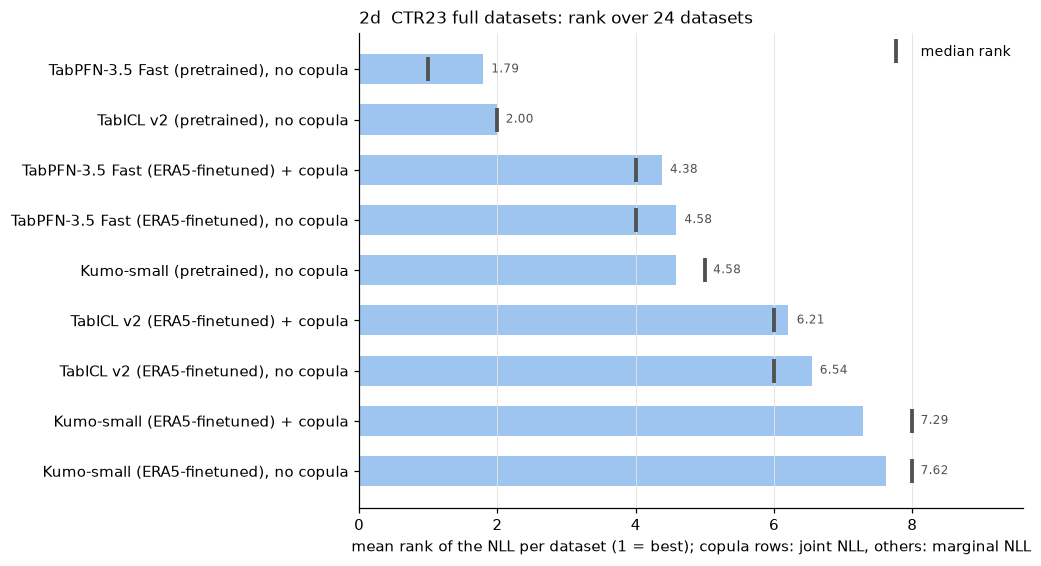

In [24]:
fig, ax = plt.subplots(figsize=(9.5, 0.45 * len(RANKS) + 1.2))
y = np.arange(len(RANKS))
ax.barh(y, RANKS["mean_rank"], height=0.6, color="#9ec5f0")
ax.plot(RANKS["median_rank"], y, "|", ms=16, mew=2.5, color="#52514e", label="median rank")
for yi, v, med in zip(y, RANKS["mean_rank"], RANKS["median_rank"]):
    ax.text(max(v, med) + 0.12, yi, f"{v:.2f}", va="center", fontsize=8, color="#52514e")
ax.set_yticks(y, RANKS.index)
ax.invert_yaxis()
ax.set_xlabel("mean rank of the NLL per dataset (1 = best); copula rows: joint NLL, others: marginal NLL")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, len(RANKS) + 0.6)
ax.legend(loc="upper right", fontsize=9)
ax.set_title(f"2d  CTR23 full datasets: rank over {len(RANK['datasets'])} datasets", loc="left", fontsize=11)
fig.tight_layout()

**Conclusion (2026-11-10, provisional: `sdwpf_f0_block` is at 3/4 folds; full CTR23 is complete for every method).**

*Episode grid (2a, 2b), cells with a CI:*

| Contrast (Δ total) | copula better | n.s. | copula worse |
|---|---|---|---|
| vs independence | 64 | 6 | 1 |
| vs autoregressive | 14 | 16 | 41 |

The copula almost always beats independence. The gains are large on `block` masks (EMNIST, KAUST `*_2`, California
f1, CTR23 `dyadic_knn`) and ≈ 0 on `random`, as expected: random masks leave little exploitable dependence. It does
**not** beat the autoregressive row in most cells (CTR23: 29 worse of 48). On the KAUST `*_1` negative control it does
not hurt vs independence.

*Full CTR23 datasets (2c, 2d):*
- **The copula helps its own marginal on the whole test fold.** TabICL v2 (ERA5-finetuned) + copula vs the same marginal alone: 16/24 datasets
  better, mean $\Delta = -0.070$, median $-0.009$ nats/point, Wilcoxon $p = 0.031$. On 64-row chunks the evidence
  is weaker: `dyadic_knn` 15/24 ($p = 0.12$), `random` 11/24 ($p = 0.77$).
- **The ERA5-finetuned marginals are the bottleneck.** Over all 24 datasets (Friedman $p = 3\cdot10^{-21}$), the
  pretrained TabPFN-3.5 Fast (mean rank $1.79$) and the pretrained TabICL v2 ($2.00$) lead. Each ERA5-finetuned marginal
  loses to its own pretrained version on 23–24 of 24 datasets (Holm $p \le 1.5\cdot10^{-4}$). Adding the copula
  improves each finetuned marginal on 15–16/24 datasets (rank gain $0.2$–$0.3$), but it does not close that gap. The
  best joint model is TabPFN-3.5 Fast (ERA5-finetuned) + copula (rank $4.38$).
- Next: score a copula on a **pretrained** marginal on CTR23 (the `PRE` recipe of §3).

---
## 3. Training with variable context and query sizes

**Question.** The §1 copulas are trained and validated at one size ($P = 32$ context points, $N = 256$ queries). Real
data come at any size (§2: $P$ up to $10^4$). Does training on variable sizes give a copula that helps at every
$(P, N)$, and how does that depend on the marginal and on the starting point?

**Setup (2026-11-09).** Nano copula, 100 k steps, val every 5 k. Each batch draws
$P \sim \mathcal U\{10,\dots,1000\}$ and $N \sim \mathcal U\{10,\dots,1000\}$ (`data.P_min/P_max/N_min/N_max`).
Three recipes per backend:

| Recipe | Marginal ($z$ source) | Copula init |
|---|---|---|
| `FT` | ERA5-finetuned marginal (§1.3) | scratch, `muon_lr = 4e-4` |
| `PT` | short-adapted marginal (200–300 steps) | resumed from `F_nano_*_A` at 1 M steps (fixed size), `muon_lr = 1e-4`, schedule reset |
| `PRE` | pretrained marginal, no adaptation | scratch, `muon_lr = 4e-4` |

**Size grid** (`baselines.size_grid_enabled`). At each validation, 32 fixed episodes per cell
$(P, N) \in \{10, 32, 100, 316, 1000\} \times \{10, 100, 1000\}$, scored on the **exact** $z$ (the GP marginal), so the
cell measures the copula alone:

$$c_{P,N} = \text{gap\_nll}_{P,N} - H_{P,N},\qquad \text{independence} = 0,\quad \text{oracle} = -H_{P,N},
\qquad \text{captured} = c_{P,N} / (-H_{P,N}),$$

with $H_{P,N}$ the GP oracle's copula headroom in the cell (nats/point). Noise: differences under $\approx 0.005$ in the
grid mean are not reliable (32 episodes per cell). The main validation set (val/…) also has variable sizes, so its
NLLs are **not comparable with §1** (oracle full $-0.014$ here vs $0.351$ there).

The final-step numbers come from the wandb-results skill's report (`filter=_nano_PN_`).

In [25]:
SG = wandb_report(
    "size_grid", "filter=_nano_PN_", "since=2026-11-01", "states=[running,finished,crashed,killed]", "sort_by=grid"
)
BK = {"tabicl": "TabICL", "tabpfn": "TabPFN", "kumo": "Kumo"}
RECIPES = {"FT": "-", "PT": "--", "PRE": ":"}  # line style per recipe; colour = backend
E3, REC3 = {}, {}
for r in SG:
    if m := re.fullmatch(r"(FT|PT|PRE)_nano_PN_(tabicl|tabpfn|kumo)", r["label"]):
        E3[BK[m[2]], m[1]] = r["run_id"]
        REC3[BK[m[2]], m[1]] = r
ORACLE_CELLS = next(r["grid_last"]["oracle_cells"] for r in SG if r["grid_last"])
PS = sorted({int(k.split("_")[0][1:]) for k in ORACLE_CELLS})
NS = sorted({int(k.split("_")[1][1:]) for k in ORACLE_CELLS})
missing = [f"{rc}_nano_PN_{b.lower()}" for b in COLORS for rc in RECIPES if (b, rc) not in E3]
print("not in W&B yet (no validation row):", missing or "none")
report_frame(SG)[
    [
        "state",
        "step",
        "marginal (= indep.)",
        "copula",
        "full",
        "copula exact z",
        "grid mean",
        "captured",
        "best full",
        "best @",
    ]
]

not in W&B yet (no validation row): none


,state,step,marginal (= indep.),copula,full,copula exact z,grid mean,captured,best full,best @
run,,,,,,,,,,
FT_nano_PN_kumo,running,90000,0.7717,-0.0130,0.7587,-0.0054,-0.0204,0.0940,0.7583,85000
PT_nano_PN_kumo,finished,100000,0.8441,-0.0199,0.8242,-0.0032,-0.0196,0.0907,0.8240,95000
PRE_nano_PN_tabicl,finished,100000,0.8108,-0.0137,0.7971,-0.0015,-0.0196,0.0903,0.7959,80000
PRE_nano_PN_kumo,running,5000,0.8576,-0.0091,0.8485,-0.0044,-0.0192,0.0885,0.8485,5000
FT_nano_PN_tabicl,finished,100000,0.7851,-0.0172,0.7679,-0.0029,-0.0180,0.0829,0.7679,100000
PRE_nano_PN_tabpfn,running,70000,0.7480,-0.0174,0.7307,-0.0029,-0.0161,0.0743,0.7304,60000
FT_nano_PN_tabpfn,running,85000,0.6557,-0.0175,0.6382,-0.0033,-0.0086,0.0395,0.6382,85000
PT_nano_PN_tabicl,finished,100000,0.8073,-0.0297,0.7775,0.0010,-0.0060,0.0275,0.7774,25000
PT_nano_PN_tabpfn,running,95000,0.7360,-0.0230,0.7131,-0.0017,-0.0043,0.0198,0.7130,85000


### 3.1 Training curves

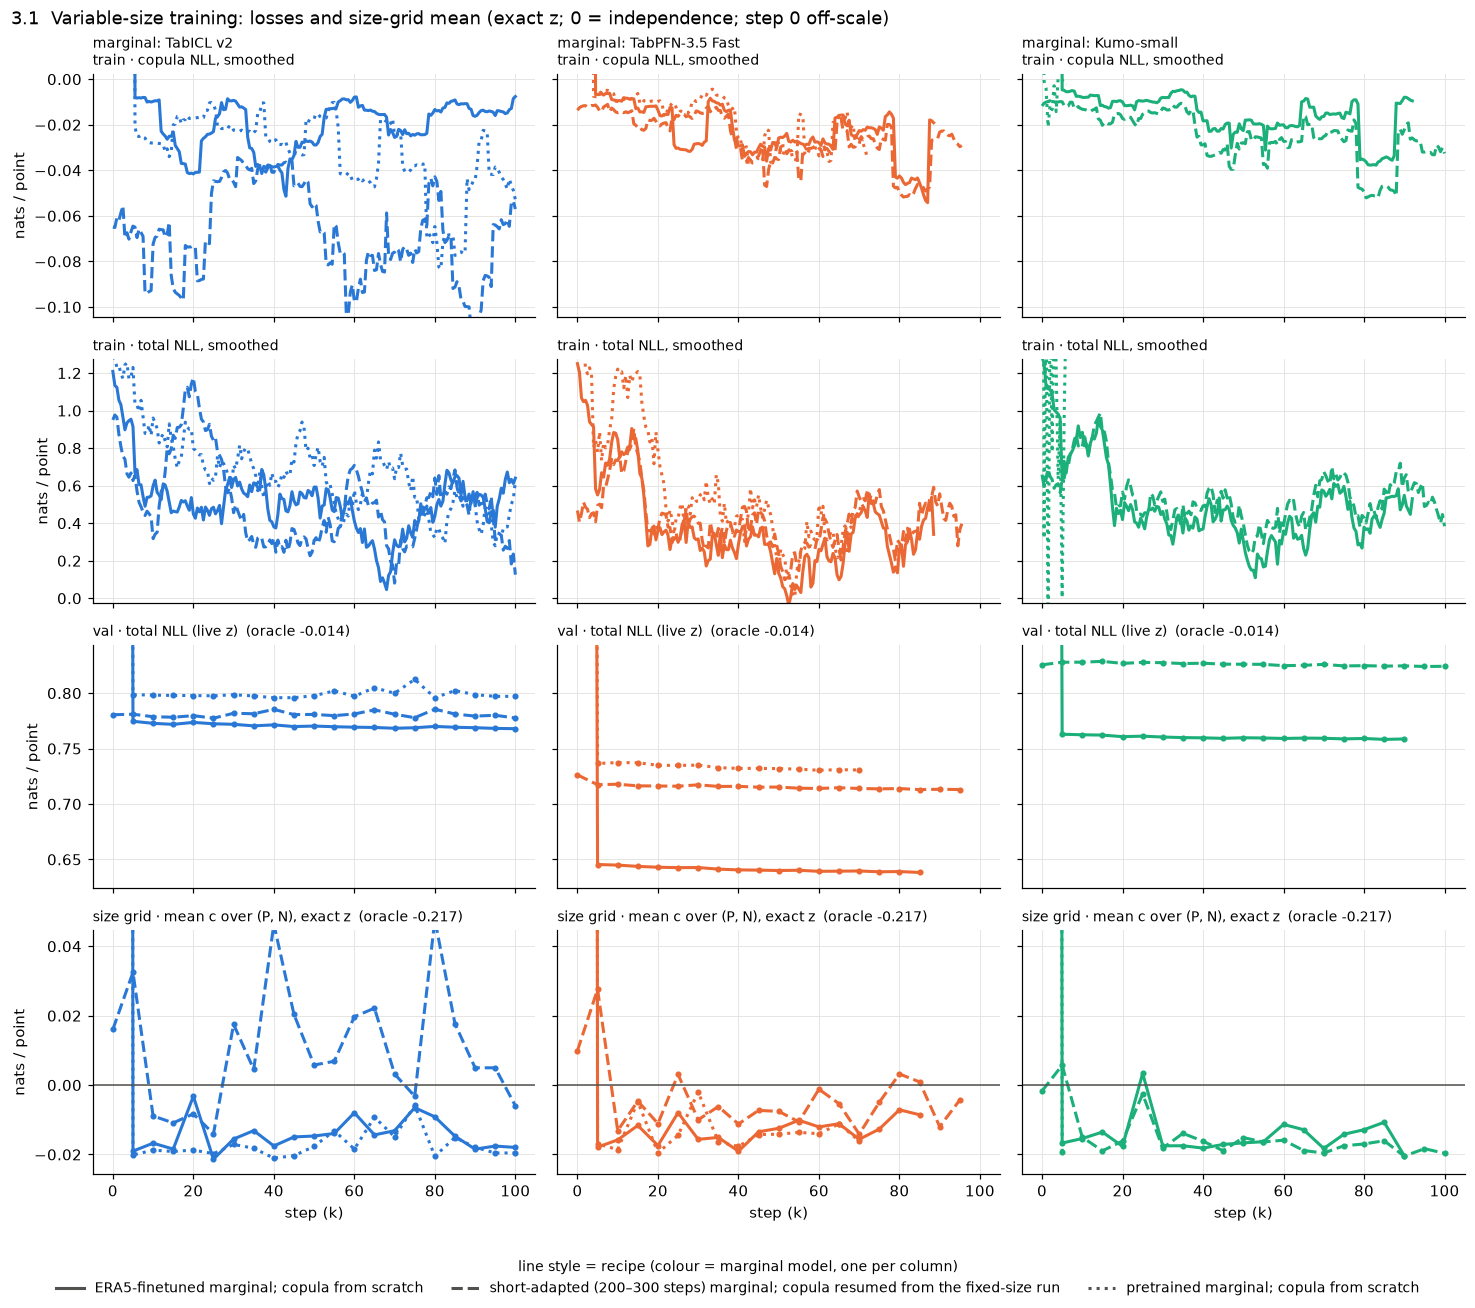

In [26]:
def grid_history(rid: str) -> pd.DataFrame:
    """Exact-z copula NLL c_{P,N} = gap_nll - headroom per cell (columns 'P10_N10', ...) at each validation step."""
    keys = {f"P{P}_N{N}": f"val/size_fit/P{P}_N{N}/gap_nll" for P in PS for N in NS}
    h, s = history(rid, list(keys.values())), run_info(rid)["summary"]
    out = pd.DataFrame({"step": h.step})
    for cell, k in keys.items():
        out[cell] = h[k] - s[k.replace("gap_nll", "copula_headroom")]
    out["grid mean"] = out[list(keys)].mean(axis=1)
    return out.dropna().reset_index(drop=True)


ROWS3 = [
    ("train/y_nll_copula", "train · copula NLL, smoothed"),
    ("train/y_nll_total", "train · total NLL, smoothed"),
    ("val/y_nll_total", "val · total NLL (live z)"),
    ("grid mean", "size grid · mean c over (P, N), exact z"),
]
fig, axes = plt.subplots(len(ROWS3), len(COLORS), figsize=(13.5, 12), sharex=True, sharey="row")
vals = {r: [] for r in range(len(ROWS3))}
for (be, rc), rid in E3.items():
    col = list(COLORS).index(be)
    h_tr, h_va, g = history(rid, TRAIN_KEYS), history(rid, ["val/y_nll_total"]), grid_history(rid)
    for row, (k, _) in enumerate(ROWS3):
        src_df = h_tr if k.startswith("train") else (h_va if k.startswith("val") else g)
        d = src_df[["step", k]].dropna()
        y = _smooth(d[k], 0.10) if k.startswith("train") else d[k]
        axes[row, col].plot(
            d.step / 1e3,
            y,
            color=COLORS[be],
            ls=RECIPES[rc],
            marker=None if k.startswith("train") else "o",
            ms=3,
            label=rc,
        )
        vals[row].append(y[d.step > 0].to_numpy())  # step 0 (untrained copula, c ~ +5 nats) is off-scale
o = next(iter(REC3.values()))
for row, (k, title) in enumerate(ROWS3):
    _ylim(axes[row, 0], vals[row], skip_frac=0.10 if row < 2 else 0.0)  # train: skip the smoothed start-up transient
    for col, be in enumerate(COLORS):
        ref = {
            2: f"  (oracle {o['last']['oracle_full']:+.3f})",
            3: f"  (oracle {o['grid_last']['oracle_mean']:+.3f})",
        }.get(row, "")
        axes[row, col].set_title(
            f"marginal: {MARGINAL_NAME[be]}\n{title}{ref}" if row == 0 else f"{title}{ref}", loc="left", fontsize=9
        )
    axes[row, 0].set_ylabel("nats / point")
for ax in axes[3]:
    ax.axhline(0, color="#52514e", lw=1)
    ax.set_xlabel("step (k)")
handles = [
    Line2D(
        [],
        [],
        color="#52514e",
        ls=ls,
        label=f"{MARGINAL_STATE[rc]} marginal"
        + (f"; {COPULA_NOTE[rc]}" if rc in COPULA_NOTE else "; copula from scratch"),
    )
    for rc, ls in RECIPES.items()
]
fig.legend(
    handles=handles,
    loc="lower center",
    ncol=3,
    fontsize=9,
    title="line style = recipe (colour = marginal model, one per column)",
    title_fontsize=9,
)
fig.suptitle(
    "3.1  Variable-size training: losses and size-grid mean (exact z; 0 = independence; step 0 off-scale)",
    x=0.01,
    ha="left",
    fontsize=12,
)
fig.tight_layout(rect=(0, 0.05, 1, 1))

### 3.2 Copula gain per context size $P$ and query size $N$

Each panel is one run at its last validation step: $c_{P,N}$ on exact $z$, in nats/point. **Blue = the copula beats
independence, red = it is worse.** All run panels share one colour scale; the oracle $-H_{P,N}$ has its own scale
(it is 10× larger).

/tmp/ipykernel_2434054/301101997.py:39: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


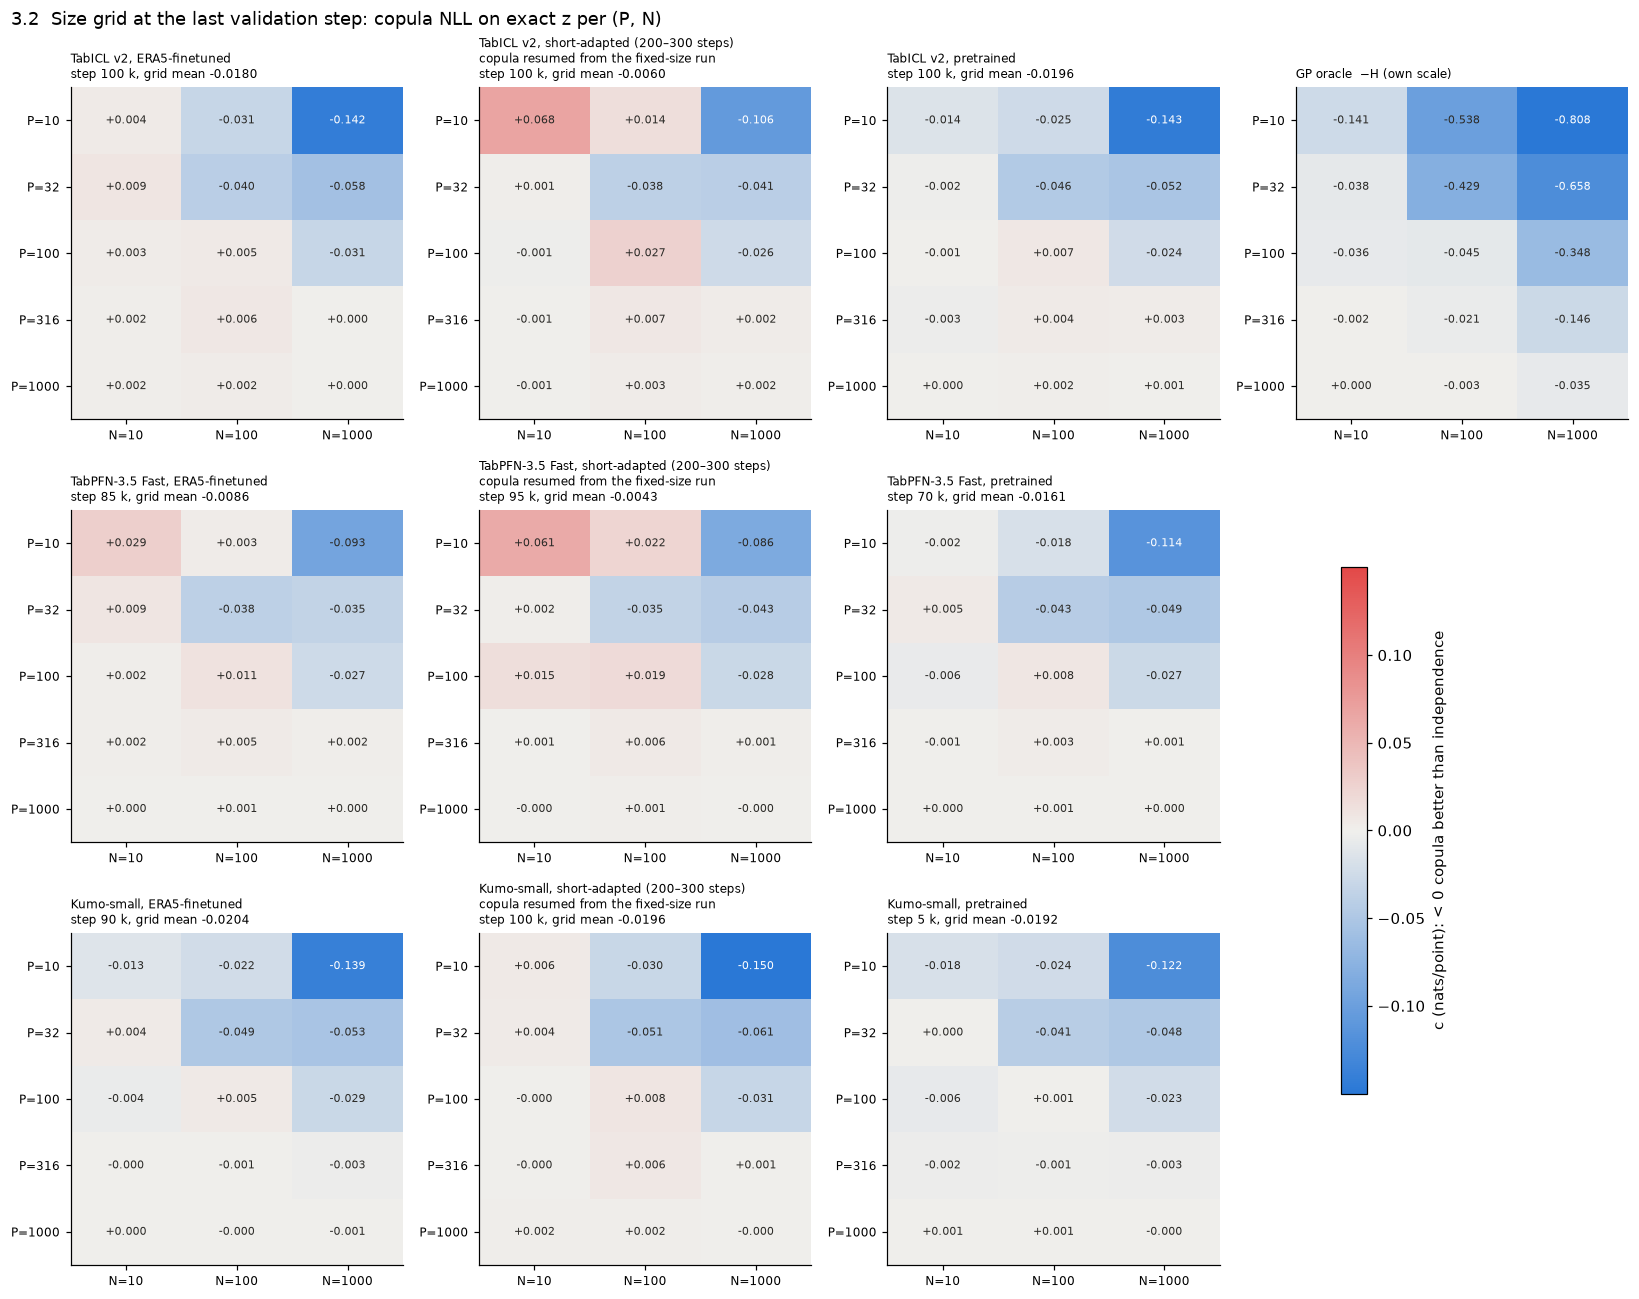

In [27]:
DIVERGING = LinearSegmentedColormap.from_list("blue_gray_red", ["#2a78d6", "#f0efec", "#e34948"])


def cell_matrix(cells: dict) -> np.ndarray:
    return np.array([[cells.get(f"P{P}_N{N}", np.nan) for N in NS] for P in PS])


def heat(ax: plt.Axes, M: np.ndarray, norm: TwoSlopeNorm, title: str) -> None:
    ax.imshow(M, cmap=DIVERGING, norm=norm, aspect="auto")
    for (a, b), v in np.ndenumerate(M):
        if np.isfinite(v):
            dark = abs(norm(v) - 0.5) > 0.35
            ax.text(b, a, f"{v:+.3f}", ha="center", va="center", fontsize=7.5, color="white" if dark else "#2b2a27")
    ax.set_xticks(range(len(NS)), [f"N={N}" for N in NS], fontsize=8)
    ax.set_yticks(range(len(PS)), [f"P={P}" for P in PS], fontsize=8)
    ax.grid(False)
    ax.set_title(title, loc="left", fontsize=8)


vmax = max(np.nanmax(np.abs(cell_matrix(r["grid_last"]["cells"]))) for r in REC3.values())
norm = TwoSlopeNorm(0.0, -vmax, vmax)
fig, axes = plt.subplots(len(COLORS), len(RECIPES) + 1, figsize=(15, 12))
for a, be in enumerate(COLORS):
    for b, rc in enumerate(RECIPES):
        ax = axes[a, b]
        if (be, rc) in REC3:
            g = REC3[be, rc]["grid_last"]
            heat(
                ax,
                cell_matrix(g["cells"]),
                norm,
                f"{run_label(be, rc, sep=chr(10))}\nstep {int(g['step']) // 1000} k, grid mean {g['mean']:+.4f}",
            )
        else:
            ax.axis("off")
            ax.text(
                0.5, 0.5, f"{run_label(be, rc)}:\nnot run yet", ha="center", va="center", fontsize=9, color="#52514e"
            )
    axes[a, -1].axis("off")
O = cell_matrix(ORACLE_CELLS)
axes[0, -1].axis("on")
heat(axes[0, -1], O, TwoSlopeNorm(0.0, -np.nanmax(np.abs(O)), np.nanmax(np.abs(O))), "GP oracle  −H (own scale)")
fig.colorbar(
    plt.cm.ScalarMappable(norm=norm, cmap=DIVERGING),
    ax=axes[1:, -1],
    fraction=0.5,
    shrink=0.8,
    label="c (nats/point): < 0 copula better than independence",
)
fig.suptitle(
    "3.2  Size grid at the last validation step: copula NLL on exact z per (P, N)", x=0.01, ha="left", fontsize=12
)
fig.tight_layout()

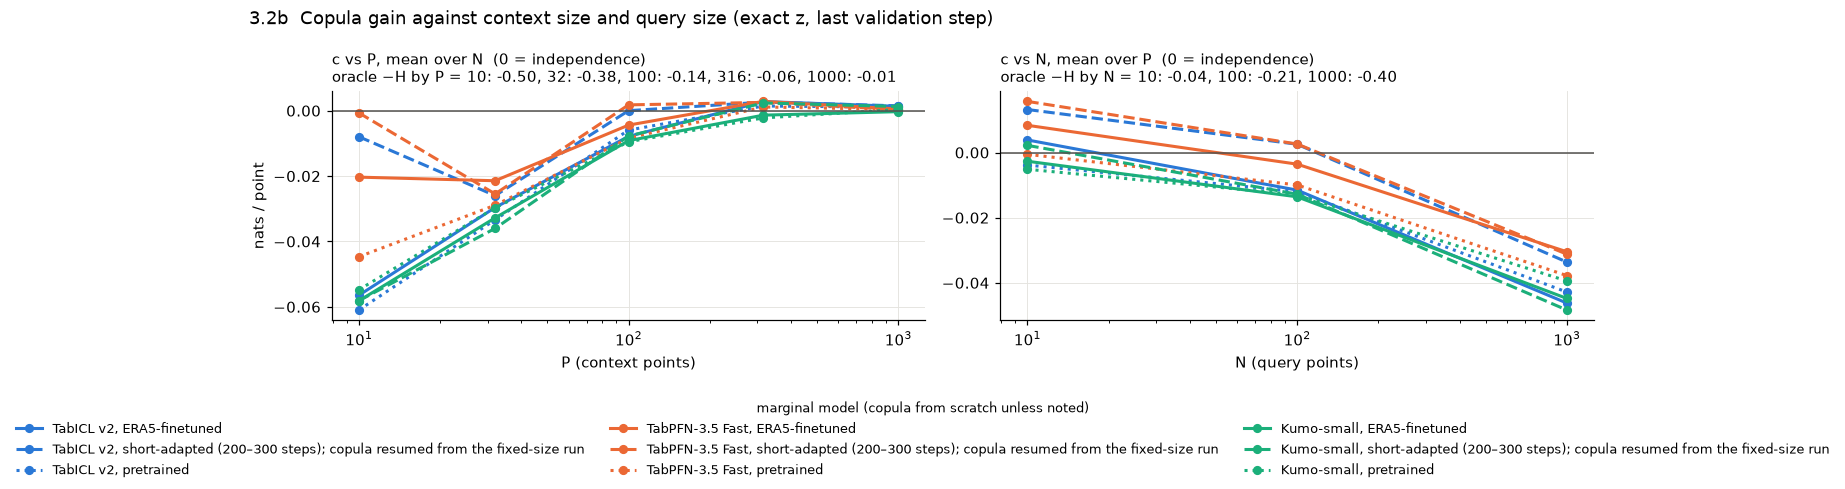

In [28]:
# Means over the other axis: c against P (mean over N) and against N (mean over P), last validation step.
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))
o = next(iter(REC3.values()))["grid_last"]
for be in COLORS:
    for rc in RECIPES:
        if (be, rc) not in REC3:
            continue
        g = REC3[be, rc]["grid_last"]
        for ax, (axis_vals, key) in zip(axes, [(PS, "P"), (NS, "N")]):
            ax.plot(
                axis_vals,
                [g[f"per_{key}"][str(v)] for v in axis_vals],
                color=COLORS[be],
                ls=RECIPES[rc],
                marker="o",
                ms=5,
                label=run_label(be, rc),
            )
for ax, (axis_vals, key, name, other) in zip(axes, [(PS, "P", "context points", "N"), (NS, "N", "query points", "P")]):
    orc = ", ".join(f"{v}: {o[f'oracle_per_{key}'][str(v)]:+.2f}" for v in axis_vals)
    ax.set_title(
        f"c vs {key}, mean over {other}  (0 = independence)\noracle −H by {key} = {orc}", loc="left", fontsize=9.5
    )
    ax.set_xscale("log")
    ax.set_xlabel(f"{key} ({name})")
    ax.axhline(0, color="#52514e", lw=1)
axes[0].set_ylabel("nats / point")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="lower center",
    ncol=3,
    fontsize=8.5,
    title="marginal model (copula from scratch unless noted)",
    title_fontsize=8.5,
)
fig.suptitle(
    "3.2b  Copula gain against context size and query size (exact z, last validation step)",
    x=0.01,
    ha="left",
    fontsize=12,
)
fig.tight_layout(rect=(0, 0.2, 1, 1))

### 3.3 Same-step comparison

Some runs are still running, so the last-step table mixes 50 k–100 k steps. Here every run with at least 50 k steps is read at
`S` = the latest validation step all of them have reached (runs that started later are listed and left out). `cells > 0` counts the $(P, N)$ cells where the copula is worse than
independence by more than the noise level (0.005 nats).

In [29]:
G3 = {k: grid_history(rid) for k, rid in E3.items()}
V3 = {
    k: history(rid, ["val/y_nll_total", "val/y_nll_marginal"]).dropna().groupby("step").last() for k, rid in E3.items()
}
MIN_STEP = 50_000  # runs that started late (fewer validation steps) are left out of the common step
last = {k: min(G3[k].step.max(), V3[k].index.max()) for k in E3}
KEEP = [k for k in E3 if last[k] >= MIN_STEP]
print(
    "left out (fewer than 50 k steps):",
    {run_label(*k): f"{int(last[k]) // 1000} k" for k in E3 if k not in KEEP} or "none",
)
S = min(last[k] for k in KEEP)
cellcols = [f"P{P}_N{N}" for P in PS for N in NS]
rows = []
for k in KEEP:
    g = G3[k].groupby("step").last()
    rows.append(
        {
            "marginal model": MARGINAL_NAME[k[0]],
            "recipe": k[1],
            "step S": int(S),
            "val full @S": V3[k].loc[S, "val/y_nll_total"],
            "val marginal @S": V3[k].loc[S, "val/y_nll_marginal"],
            "grid mean @S": g.loc[S, "grid mean"],
            "grid mean, P ≤ 32": g.loc[S, [c for c in cellcols if int(c.split("_")[0][1:]) <= 32]].mean(),
            "cells > 0 @S": int((g.loc[S, cellcols] > 0.005).sum()),
            "best grid mean": g["grid mean"].iloc[1:].min(),
            "best @": int(g["grid mean"].iloc[1:].idxmin()),
        }
    )
pd.DataFrame(rows).set_index(["marginal model", "recipe"]).sort_values("grid mean @S")

left out (fewer than 50 k steps): {'Kumo-small, pretrained': '5 k'}


step S  val full @S  val marginal @S  grid mean @S  grid mean, P ≤ 32  cells > 0 @S  best grid mean  best @
marginal model  recipe                                                                                                             
Kumo-small      PT       70000       0.8260           0.8441       -0.0196            -0.0470             1         -0.0205   90000
                FT       70000       0.7593           0.7717       -0.0183            -0.0401             0         -0.0204   90000
TabPFN-3.5 Fast PRE      70000       0.7307           0.7480       -0.0161            -0.0368             2         -0.0195   20000
                FT       70000       0.6396           0.6557       -0.0156            -0.0353             1         -0.0191   40000
TabICL v2       PRE      70000       0.7999           0.8108       -0.0149            -0.0408             3         -0.0211   40000
TabPFN-3.5 Fast PT       70000       0.7140           0.7360       -0.0141            -0.0348             1         -0.0141   70000
TabICL v2       FT       70000       0.7683           0.7851       -0.0131            -0.0294             1         -0.0213   25000
                PT       70000       0.7810           0.8073        0.0032             0.0029             5         -0.0140   25000

**Conclusion (2026-11-10, provisional: the TabPFN-3.5 Fast runs (ERA5-finetuned, short-adapted, pretrained) and the ERA5-finetuned Kumo-small run are at 70–95 k steps; the pretrained Kumo-small run is at 5 k).**

Recipes, by marginal: ERA5-finetuned (`FT`), short-adapted with the copula resumed from the fixed-size run (`PT`),
pretrained (`PRE`).

- **The full NLL is set by the marginal.** Ordered by val total at the last step: TabPFN-3.5 Fast ERA5-finetuned
  $0.638$ (85 k), short-adapted $0.713$, pretrained $0.731$; Kumo-small ERA5-finetuned $0.759$; TabICL v2
  ERA5-finetuned $0.768$, short-adapted $0.778$, pretrained $0.797$; Kumo-small short-adapted $0.824$ (oracle
  $-0.014$). The copula term is only $-0.013$ to $-0.030$; the marginal column has the same order.
- **The copula captures 2–9 % of the oracle gain on the grid** (last-step grid mean $-0.004$ to $-0.020$, oracle
  $-0.217$). A single validation step is noisy: the grid mean moves by about $\pm 0.01$ from one validation to the
  next (3.1). At the common step $S = 70$ k (§3.3), seven of the eight runs lie between $-0.013$ and $-0.020$, near the
  noise level. The recipe and the marginal model do not separate them. The exception is TabICL v2 short-adapted with
  the copula resumed ($+0.003$).
- **Where it helps (3.2):** small context and many queries. At $(P, N) = (10, 1000)$, $c \approx -0.09$ to $-0.15$
  (oracle $-0.81$). At $P \ge 316$, $c \approx 0$, but the oracle gain there is small too ($-0.06$, $-0.01$). At
  $N = 10$ (oracle $-0.043$, mean over $P$) the copula gains nothing: $-0.005$ to $+0.004$ for most runs, and $+0.008$
  to $+0.016$ (worse than independence) for TabPFN-3.5 Fast ERA5-finetuned and for both resumed short-adapted runs on
  TabICL v2 and TabPFN-3.5 Fast.
- **Resuming the fixed-size copula fails at small sizes, except on Kumo-small.** At $(10, 10)$: $+0.068$ (TabICL v2)
  and $+0.061$ (TabPFN-3.5 Fast). The $P = 32$, $N = 256$ copula does not transfer, and `muon_lr = 1e-4` does not
  recover it. The TabICL v2 resumed run has the largest live-$z$ copula gain ($-0.030$) but $+0.001$ on exact $z$. It
  is fitting the short-adapted marginal's PIT errors, not the GP correlation.
- **The grid mean plateaus by ≈ 10 k steps (3.1).** The best grid step varies from 20 k to 90 k, but it is within
  noise of the 10 k value. More steps of this recipe do not buy copula quality. A plausible reason, not tested here,
  is that the nano copula is limited by capacity or by the objective, not by the number of steps.

---
## 4. The copula gap: ICL head vs the attainable and Bayes Gaussian copulas

**Question.** On the table2 cells the ICL head gains about $0.07$ nats/point over independence, while the best
Gaussian copula under the same frozen TabICL marginal gains about $0.9$. What is reachable by a copula that only
sees the context, at full rank and at rank $r$, and where does the rest of the gap come from?

**Setup.** $z_j=\Phi^{-1}(\hat F_j(y_j))$ with $\hat F$ the frozen TabICL marginal; $D=(x_C,y_C,x_Q)$ is what the
head sees; $\vartheta$ is everything that generated the episode (kernel hyperparameters, the hidden kernel warp $g$,
the kernel family $k$, the active dims $S$). For any information $\mathcal G$ and correlation $R$,
$$
\mathbb E[-\log c_R(z)\mid\mathcal G]/N=\ell(R,M_{\mathcal G}),\qquad
\ell(R,M)=\tfrac1{2N}\big[\log\det R+\mathrm{tr}((R^{-1}-I)M)\big],\qquad M_{\mathcal G}=\mathbb E[zz^\top\mid\mathcal G],
$$
linear in $M$ ($0$ = independence).

**Reachability.** For a family $\mathcal R$ (all correlations, or rank $r$), $f_{\mathcal R}(M)=\min_{R\in\mathcal R}\ell(R,M)$
is concave (a minimum of affine maps), so with $V_{\mathcal R}(\mathcal G)=\mathbb E f_{\mathcal R}(M_{\mathcal G})$:

1. any $\mathcal G$-measurable $R$ has $\mathbb E\,\ell(R,M_\vartheta)=\mathbb E\,\ell(R,M_{\mathcal G})\ge V_{\mathcal R}(\mathcal G)$, with
   equality for $R_{\mathcal G}=\arg\min_{\mathcal R}\ell(R,M_{\mathcal G})$;
2. $\mathcal G\subseteq\mathcal H\Rightarrow V(\mathcal H)\le V(\mathcal G)$ (conditional Jensen).

Hence, at every rank,
$$
\underbrace{V(\vartheta)}_{R^\dagger}\le\underbrace{V(D,g,k,S)}_{R_{\text{Bayes}}}\le\underbrace{V(D)}_{R^*\ \text{(context-only target)}}\le\mathbb E\,\ell(R_{\text{icl}}).
$$
$R_{\text{Bayes}}$ (`copula_inter.data.gp_bayes`, $\theta$ importance-sampled from the generator's prior) is in the head's
family but is a function of $g,k,S$, which the head never receives; it bounds the context-only target $R^*$, it is
not one. The measured gap $\mathbb E\,\ell(R_{\text{icl}})-V_r(D,g,k,S)$ is head inefficiency plus the value of knowing
$(g,k,S)$; only the sum is identified.

**Where the value of information comes from.** $M_{\mathcal G}=C_{\mathcal G}+m_{\mathcal G}m_{\mathcal G}^\top$ with
$m_{\mathcal G}=\mathbb E[z\mid\mathcal G]$, the marginal's bias. Given the context only,
$M_D=\mathbb E[C_I\mid D]+\mathbb E[m_Im_I^\top\mid D]$ ($I=(D,g,k,S)$; $m_D=0$ for a marginal calibrated given $D$):
the marginal's error is dependence for a context-only copula through its spread, not its realised direction. For a
one-factor $R=I+c\,vv^\top$ ($|v|=1$, before renormalisation) and $q=v^\top Mv$, the best $c=q-1$ gives
$\ell^*=-(q-1-\log q)/(2N)$: a known bias direction ($q\approx|m|^2\approx0.6N$) is worth $\approx-0.3$ nats/point,
a direction spread over $k$ equally likely ones ($q\approx1+0.6N/k$) much less.

**Runs (2026-11-16).** `eval.runners.copula_gap_diag` (branch `copula-gap-diag`), 150 episodes per cell, CPU,
$M,m$ from 8192 known-$\theta$ draws, $M_{\text{Bayes}},m_{\text{Bayes}}$ from 65 536 prior draws (4096 kept), copula
`copula_nano/copula-finetune-marginal-float32/step_0630000`, marginal `marginal_finetune_era5_run1/step_0177600`.
`table2_rbf_nowarp` is the rbf cell without the hidden kernel warp ($g=\mathrm{id}$), where $R_{\text{Bayes}}$ knows only
$(k,S)$ beyond the context. Rows (all $\ell$ under the true $M$):

| row | definition |
|---|---|
| any copula (bound) | $\tfrac1N\mathbb E[-\log p_U(U)]$, below every copula |
| $R^\dagger$, rank $r$ | $\arg\min\ell(R,M)$, all correlations / rank-$r$ covnorm |
| $R_{\text{Bayes}}$, rank $r$ | the same fitted to $M_{\text{Bayes}}$ |
| corr$(z)$ | $\mathrm{corr}(M-mm^\top)$: dependence given $\vartheta$, no bias |
| bias factor | best $\mathrm{normalize}(I+c\,mm^\top)$: the bias direction alone |
| ICL, ICL sharpened | the head's $R_{\text{icl}}$; best $\mathrm{normalize}(R_{\text{icl}}^\beta)$ (oracle-tuned $\beta$) |

In [ ]:
# Mean l (nats/point, 0 = independence) per row and cell; Bayes rows also over the episodes with ESS >= 10.
GAP = ROOT / "eval/results/copula_gap"
GAP_CELLS = {
    "rbf": "table2_rbf",
    "Matérn-3/2": "table2_matern32",
    "RQ": "table2_rational_quadratic",
    "systematic": "table2_systematic",
    "rbf, no warp": "table2_rbf_nowarp",
}
GAP_ROWS = {
    "any_copula_bound": "any copula (bound)",
    "attainable": "R† full rank",
    **{f"attainable_r{r}": f"R† rank {r}" for r in (1, 2, 4, 16)},
    "bayes_attainable": "R_Bayes full rank",
    **{f"bayes_attainable_r{r}": f"R_Bayes rank {r}" for r in (1, 2, 4, 16)},
    "corr_z": "corr(z), given θ",
    "bias_factor": "bias factor (along m)",
    "icl": "ICL head",
    "icl_sharpened": "ICL sharpened",
    "oracle_posterior": "R_po",
}
LADDER = {
    name: pd.DataFrame(json.load(open(GAP / cell / "ladder.json"))["episodes"])
    for name, cell in GAP_CELLS.items()
    if (GAP / cell / "ladder.json").exists()
}
GAP_MEAN = pd.DataFrame({name: df[list(GAP_ROWS)].mean() for name, df in LADDER.items()}).rename(index=GAP_ROWS)
GAP_MED = pd.DataFrame({name: df[list(GAP_ROWS)].median() for name, df in LADDER.items()}).rename(index=GAP_ROWS)
ok = {name: df[df.bayes_ess >= 10] for name, df in LADDER.items()}
bayes_keys = [k for k in GAP_ROWS if k.startswith("bayes_")]
GAP_ESS10 = pd.DataFrame({name: df[bayes_keys].mean() for name, df in ok.items()}).rename(index=GAP_ROWS)
GAP_ESS10.index = [f"{i} (ESS ≥ 10)" for i in GAP_ESS10.index]
info = pd.DataFrame(
    {
        name: {
            "episodes": len(df),
            "share ESS < 10": (df.bayes_ess < 10).mean(),
            "mean(m²) (bias)": df.mean_bias_sq.mean(),
            "mean diag M": df.m_diag.mean(),
            "cos(m_Bayes, m)": df.bayes_bias_cos.mean(),
            "ICL sharpening β": df.icl_sharpen_beta.mean(),
            "ICL / R_Bayes (ESS ≥ 10)": ok[name].icl.mean() / ok[name].bayes_attainable.mean(),
            "ICL / corr(z)": df.icl.mean() / df.corr_z.mean(),
        }
        for name, df in LADDER.items()
    }
)
display(GAP_MEAN.style.format("{:+.3f}").set_caption("Mean l over all episodes"))
display(GAP_ESS10.style.format("{:+.3f}").set_caption("Bayes rows, episodes with importance ESS >= 10"))
display(info.style.format("{:.3g}"))

,rbf,Matérn-3/2,RQ,systematic,"rbf, no warp"
any copula (bound),-1.084,-0.878,-0.995,-0.829,-0.629
R† full rank,-0.965,-0.771,-0.877,-0.724,-0.538
R† rank 1,-0.445,-0.367,-0.423,-0.344,-0.244
R† rank 2,-0.793,-0.599,-0.713,-0.549,-0.365
R† rank 4,-0.857,-0.659,-0.769,-0.608,-0.421
R† rank 16,-0.947,-0.753,-0.859,-0.705,-0.515
R_Bayes full rank,-0.789,-0.665,-0.210,-0.634,-0.269
R_Bayes rank 1,-0.381,-0.316,-0.322,-0.303,-0.134
R_Bayes rank 2,-0.637,-0.500,-0.216,-0.469,-0.166
R_Bayes rank 4,-0.699,-0.557,-0.257,-0.524,-0.204


,rbf,Matérn-3/2,RQ,systematic,"rbf, no warp"
R_Bayes full rank (ESS ≥ 10),-0.821,-0.665,-0.712,-0.623,-0.356
R_Bayes rank 1 (ESS ≥ 10),-0.382,-0.320,-0.354,-0.295,-0.149
R_Bayes rank 2 (ESS ≥ 10),-0.655,-0.501,-0.562,-0.452,-0.210
R_Bayes rank 4 (ESS ≥ 10),-0.720,-0.561,-0.615,-0.508,-0.263
R_Bayes rank 16 (ESS ≥ 10),-0.807,-0.652,-0.700,-0.607,-0.341


,rbf,Matérn-3/2,RQ,systematic,"rbf, no warp"
episodes,150,150,150,150,150
share ESS < 10,0.147,0.107,0.153,0.0733,0.247
mean(m²) (bias),0.636,0.562,0.615,0.541,0.401
mean diag M,1.02,1.03,1.04,1.03,0.996
"cos(m_Bayes, m)",0.938,0.936,0.93,0.937,0.759
ICL sharpening β,1.2,1.12,1.17,1.07,1.31
ICL / R_Bayes (ESS ≥ 10),0.0818,0.087,0.0993,0.0941,0.215
ICL / corr(z),0.436,0.332,0.415,0.36,0.452


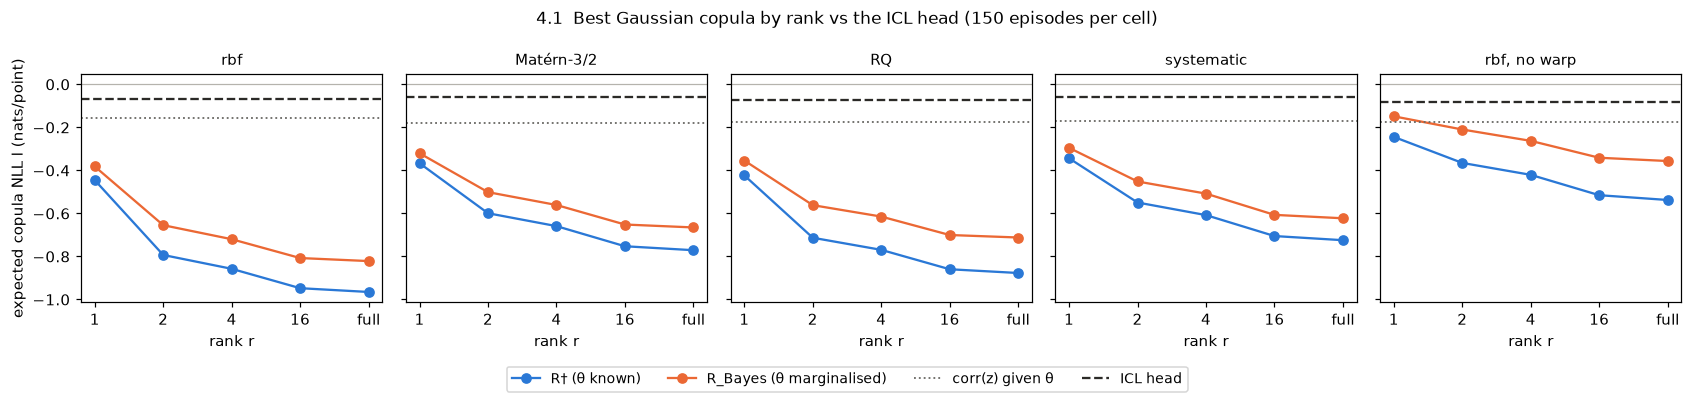

In [ ]:
# l against rank r: best Gaussian copula with theta known (R†) and with theta marginalised (R_Bayes, ESS >= 10),
# against the ICL head (rank 512) and corr(z). Lower is better; 0 = independence.
RANKS = [1, 2, 4, 16, "full"]
fig, axes = plt.subplots(1, len(LADDER), figsize=(3.1 * len(LADDER), 3.6), sharey=True)
for ax, (name, df) in zip(axes, LADDER.items()):
    dfo = ok[name]
    x = np.arange(len(RANKS))
    att = [df[f"attainable_r{r}"].mean() if r != "full" else df.attainable.mean() for r in RANKS]
    bay = [dfo[f"bayes_attainable_r{r}"].mean() if r != "full" else dfo.bayes_attainable.mean() for r in RANKS]
    ax.plot(x, att, "-o", ms=6, color=COLORS["TabICL"], label="R† (θ known)")
    ax.plot(x, bay, "-o", ms=6, color=COLORS["TabPFN"], label="R_Bayes (θ marginalised)")
    ax.axhline(df.corr_z.mean(), color="#6b6a66", lw=1.2, ls=":", label="corr(z) given θ")
    ax.axhline(df.icl.mean(), color="#2b2a27", lw=1.5, ls="--", label="ICL head")
    ax.axhline(0, color="#b5b3ad", lw=0.8)
    ax.set_xticks(x, [str(r) for r in RANKS])
    ax.set_xlabel("rank r")
    ax.set_title(name, fontsize=10)
axes[0].set_ylabel("expected copula NLL l (nats/point)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4, fontsize=9, bbox_to_anchor=(0.5, 0.0))
fig.suptitle("4.1  Best Gaussian copula by rank vs the ICL head (150 episodes per cell)", fontsize=11)
fig.tight_layout(rect=(0, 0.08, 1, 1))

**Conclusion (2026-11-16; 150 episodes per cell, $\ell$ in nats/point under the true $M$; Bayes rows on ESS $\ge10$).**

- **The best Gaussian copula by rank.** rbf: $R^\dagger$ rank 1/2/4/16/full $=-0.45/-0.79/-0.86/-0.95/-0.97$,
  $R_{\text{Bayes}}$ $=-0.38/-0.66/-0.72/-0.81/-0.82$. In every cell rank $16$ is within $0.02$ of full rank for
  both, so the head's rank ($512$) is not the limit. With the warp, $R_{\text{Bayes}}$ keeps $79$–$87\,\%$ of
  $R^\dagger$ at every rank: marginalising $\theta$ costs little.
- **These copulas are not reachable from the context.** $R_{\text{Bayes}}$ knows the hidden warp, the family and the
  active dims, and $\cos(m_{\text{Bayes}},m)\approx0.93$–$0.94$: with the geometry known, the GP posterior mean
  predicts the TabICL marginal's error ($\overline{m^2}=0.54$–$0.64$ of $\mathbb E z^2\approx1$), and the copula turns
  that into likelihood (a single factor along $m$ alone gives $-0.29$ to $-0.36$). By the chain above the head is
  bounded by $V(D)\in[\ell(R_{\text{Bayes}}),\ell(R_{\text{icl}})]$, not by $\ell(R_{\text{Bayes}})$.
- **Without the warp the gap shrinks almost threefold.** On `rbf, no warp` (where $R_{\text{Bayes}}$ knows only
  $k,S$) the bias drops to $0.40$, $\cos$ to $0.76$, $R_{\text{Bayes}}$ to $-0.36$; the gap ICL $\to R_{\text{Bayes}}$
  goes from $0.75$ to $0.28$ and the head reaches $22\,\%$ of $R_{\text{Bayes}}$, against $8$–$10\,\%$ with the warp.
- **The head captures $33$–$45\,\%$ of corr$(z)$** (dependence given $\theta$, no bias), and is not merely too weak:
  its best rescaling $\mathrm{normalize}(R_{\text{icl}}^\beta)$ has $\beta\approx1.1$–$1.3$ and gains only
  $0.014$–$0.021$. What is missing is the pattern, not its strength.
- **Caveat.** With 65 536 prior draws, $7$–$25\,\%$ of episodes have an importance ESS $<10$; the mixture then
  collapses to one component and $R_{\text{Bayes}}$ can be far worse than independence (RQ, all episodes: mean
  $-0.21$, median $-0.68$). Restricting to ESS $\ge10$ selects slightly easier episodes.

**Next.** Estimate the context-only target $V(D)$: marginalise the warp with a sampler that does not collapse
(SMC / tempered importance sampling over $g$), or measure an achievable point with a richer context-only copula.

---
## 5. Expected-loss target, the $z_{\text{train}}$ ablation and the gap to $V(D)$ (2026-11-16 → 11-17)

**Question.** Section 4 bounds the head by $V(D)\in[\ell(R_{\text{Bayes}}),\ell(R_{\text{icl}})]$, with a wide gap. Three
questions: (i) does a lower-variance training target help; (ii) how much does the head take from the context labels
$z_{\text{train}}$; (iii) where, between $\ell(R_{\text{Bayes}})$ and the head, are the nats lost?

**Targets.** For the head's $R$ on a query block of $N$ points, with $\ell$ as in section 4,
$$
\texttt{cop\_draw}=\ell(R,zz^\top),\qquad
\texttt{cop\_exp}=\ell(R,\hat M),\quad \hat M=\tfrac1{32}\textstyle\sum_{s=1}^{32}z^{(s)}z^{(s)\top},\ z^{(s)}\sim p(z\mid y_C,\vartheta).
$$
$\ell$ is linear in $M$ and $\mathbb E[\hat M\mid D,\vartheta]=\mathbb E[zz^\top\mid D,\vartheta]$, so both targets have the same
expectation and the same minimiser; the expected (Rao–Blackwellised) one only has less gradient noise.

**Arms.** All fine-tune `copula-nano-finetune-marginal-float32` with `experiment=amortized_reference` (rank 512,
$P=32$, $N=256$, $d=10$ systematic episodes, `muon_lr=1e-4`, 200 k steps planned), branch `amortized-reference`
(uncommitted). Same seed, data order and schedule in every arm, so the validation noise is shared: compare arms paired.

| arm | keys | site, job | W&B | state |
|---|---|---|---|---|
| draw | `training.copula_target=draw` | Nancy A40, 7036010 | `pstg268l` | stopped at 120 k (10 h walltime) |
| expected | `training.copula_target=expected` | Nancy A40, 7036012 | `ydbee66n` | stopped at 115 k |
| expected, x_kernel head | + `data.head_features=x_kernel` | Nancy A40, 7036013 | `9al4gwop` | stopped at 115 k |
| $z_{\text{train}}$ observed | expected + `model.z_train_input=observed` | Grenoble A5000, 3170787 | `m6w8rfg0` | running (160 k) |
| $z_{\text{train}}$ shuffled | `model.z_train_input=shuffled` | Grenoble A5000, 3170789 | `y5f82a3g` | running (155 k) |
| $z_{\text{train}}$ zero | `model.z_train_input=zero` | Grenoble A5000, 3170788 | `0kjg1wyr` | running (155 k) |

- `x_kernel`: the head gets the inputs in kernel space (active dims selected, hidden warp applied). No real model has
  them: this arm is a rung of the information ladder, not a candidate.
- `shuffled` permutes $z_{\text{train}}$ over the valid context rows: its distribution is kept, the $x\leftrightarrow z$
  pairing is broken. `zero` replaces it by zeros (out of distribution at step 0).

,last step (k),cop_exp start,cop_draw start,cop_exp 100–115 k,cop_draw 100–115 k,cop_exp 140–155 k,cop_draw 140–155 k
draw target,120,-0.1251,-0.1233,-0.1288,-0.1279,–,–
expected target,115,-0.1251,-0.1233,-0.1339,-0.1333,–,–
"expected, x_kernel head",115,-0.2627,-0.2580,-0.3391,-0.3334,–,–
z_train observed,160,-0.1251,-0.1233,-0.1342,-0.1333,-0.1368,-0.1357
z_train shuffled,155,-0.1144,-0.1143,-0.1267,-0.1264,-0.1291,-0.1289
z_train zero,155,+0.0832,+0.0825,-0.1259,-0.1256,-0.1286,-0.1283


,a - b,s.e.,a better (share),steps
expected target − draw target (5–115 k),-0.0061,0.0003,100%,23
"expected, x_kernel head − expected target (5–115 k)",-0.2005,0.0009,100%,23
z_train observed − expected target (5–115 k),-0.0002,0.0002,61%,23
z_train observed − z_train shuffled (5–155 k),-0.0071,0.0002,100%,31
z_train observed − z_train zero (5–155 k),-0.0086,0.0003,100%,31
z_train shuffled − z_train zero (5–155 k),-0.0015,0.0002,100%,31


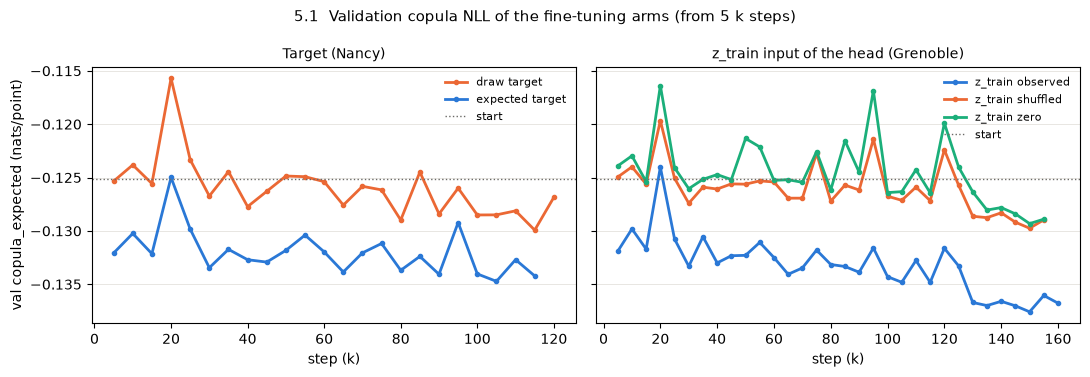

In [ ]:
# Validation copula NLL of the amortized-reference arms (nats/point, 0 = independence; lower is better).
# copula_draw: l(R, z z^T) on one draw; copula_expected: l(R, M_hat), M_hat from 32 draws of z given (y_C, theta).
# All arms share the seed, the data order and the schedule, so their validation noise is shared: compare them paired.
AR_RUNS = {
    "draw target": "pstg268l",  # Nancy A40, stopped by the 10 h walltime
    "expected target": "ydbee66n",
    "expected, x_kernel head": "9al4gwop",
    "z_train observed": "m6w8rfg0",  # Grenoble A5000, 36 h walltime
    "z_train shuffled": "y5f82a3g",
    "z_train zero": "0kjg1wyr",
}
AR_KEYS = ["val/copula_draw", "val/copula_expected"]
AR = {k: history(rid, AR_KEYS).dropna().groupby("step").last() for k, rid in AR_RUNS.items()}
AR_WINDOWS = {"start": (0, 0), "100–115 k": (100_000, 115_000), "140–155 k": (140_000, 155_000)}
rows = {}
for name, h in AR.items():
    r: dict[str, float] = {"last step (k)": h.index.max() / 1000}
    for w, (a, b) in AR_WINDOWS.items():
        sel = h.loc[a:b]
        if len(sel) == (b - a) // 5000 + 1:  # every validation of the window logged
            r[f"cop_exp {w}"] = sel["val/copula_expected"].mean()
            r[f"cop_draw {w}"] = sel["val/copula_draw"].mean()
    rows[name] = r
AR_TABLE = pd.DataFrame(rows).T
display(
    AR_TABLE.style.format("{:+.4f}", na_rep="–")
    .format("{:.0f}", subset=["last step (k)"])
    .set_caption("Mean over the validations of each window")
)


def paired(a: str, b: str, lo: int, hi: int, key: str = "val/copula_expected") -> dict:
    """a - b at the same validation steps in [lo, hi]: mean, s.e. over steps, share of steps where a is better."""
    d = (AR[a][key] - AR[b][key]).loc[lo:hi].dropna()
    return {"a - b": d.mean(), "s.e.": d.std() / np.sqrt(len(d)), "a better (share)": (d < 0).mean(), "steps": len(d)}


AR_PAIRS = [
    ("expected target", "draw target", 5_000, 115_000),
    ("expected, x_kernel head", "expected target", 5_000, 115_000),
    ("z_train observed", "expected target", 5_000, 115_000),  # replication: same recipe, other site
    ("z_train observed", "z_train shuffled", 5_000, 155_000),
    ("z_train observed", "z_train zero", 5_000, 155_000),
    ("z_train shuffled", "z_train zero", 5_000, 155_000),
]
display(
    pd.DataFrame({f"{a} − {b} ({lo // 1000}–{hi // 1000} k)": paired(a, b, lo, hi) for a, b, lo, hi in AR_PAIRS})
    .T.style.format({"a - b": "{:+.4f}", "s.e.": "{:.4f}", "a better (share)": "{:.0%}", "steps": "{:.0f}"})
    .set_caption("Paired differences of copula_expected (s.e. ignores the autocorrelation of the steps)")
)

# Two panels, three series at most each; the x_kernel arm (-0.33) is off this scale and stays in the tables.
AR_PANELS = {
    "Target (Nancy)": {"draw target": COLORS["TabPFN"], "expected target": COLORS["TabICL"]},
    "z_train input of the head (Grenoble)": {
        "z_train observed": COLORS["TabICL"],
        "z_train shuffled": COLORS["TabPFN"],
        "z_train zero": COLORS["Kumo"],
    },
}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, (title, series) in zip(axes, AR_PANELS.items()):
    for name, color in series.items():
        h = AR[name].loc[5_000:]
        ax.plot(h.index / 1000, h["val/copula_expected"], "-o", ms=3, lw=2, color=color, label=name)
    ax.axhline(AR["expected target"].loc[0, "val/copula_expected"], color="#6b6a66", lw=1, ls=":", label="start")
    ax.grid(axis="y", color="#e4e2dd", lw=0.6)
    ax.set_xlabel("step (k)")
    ax.set_title(title, fontsize=10)
    ax.legend(fontsize=8, frameon=False, loc="upper right")
axes[0].set_ylabel("val copula_expected (nats/point)")
fig.suptitle("5.1  Validation copula NLL of the fine-tuning arms (from 5 k steps)", fontsize=11)
fig.tight_layout()

**5.1 Result (2026-11-17; validation `copula_expected`, nats/point, paired over the same steps; start $=-0.125$).**

- **The expected target helps, a little.** expected $-$ draw $=-0.0061$, lower at 23 of 23 validations
  (100–115 k: $-0.134$ vs $-0.129$). Fine-tuning gains $0.009$ with the expected target and $0.004$ with draw. The
  recipe replicates across sites: $z_{\text{train}}$ observed (Grenoble) $-$ expected (Nancy) $=-0.0002$.
- **Giving the head the geometry is worth 30× more.** x_kernel $-$ expected $=-0.200$ (100–115 k: $-0.339$).
  $-0.138$ of it is there at step 0, before the head has seen any x_kernel batch.
- **The head uses the labels, a little.** observed $-$ shuffled $=-0.0071$ and observed $-$ zero $=-0.0086$, each lower
  at 31 of 31 validations; shuffled $-$ zero $=-0.0015$. At 140–155 k, the head without labels has gained $0.004$
  over the start, the head with them $0.012$: the labels are worth $\approx0.008$ nats/point, most of the fine-tuning
  gain.
- **The curves are not flat yet.** A $\approx0.003$ step down at 130 k appears in all three Grenoble arms (shared data
  order and schedule), so the differences hold. Zero starts at $+0.083$ (out-of-distribution input) and recovers
  within 5 k steps.

In [ ]:
# Rescoring on table2_systematic (logs/ar_light.py, 150 episodes, l under the true M, nats/point, 0 = independence).
# Start = the source checkpoint (section 4 ladder). Only systematic is valid: the saved moments of the other cells
# do not match the regenerated episodes (see the caveat below).
GAP_BASE = next(
    q / "eval/results/copula_gap"
    for p in [ROOT, *ROOT.parents]
    for q in (p, p / ".claude/worktrees/copula-gap-diag")
    if (q / "eval/results/copula_gap/table2_systematic/ladder.json").is_file()
)
VALID_CELLS = ["table2_systematic"]
_tok = re.compile(r"(\w+)=([+-]?\d+\.\d+)±(\d+\.\d+)")
LIGHT = []
for f in sorted((ROOT / "logs/g5k").glob("light_*.log")):
    for line in f.read_text().splitlines():
        if not line.startswith("RESULT "):
            continue
        parts = line.split()
        tag = parts[2] if "=" not in parts[2] else "prior reference"
        rec = {"cell": parts[1], "tag": tag}
        for k, v, se in _tok.findall(line):
            rec[k], rec[f"{k} se"] = float(v), float(se)
        LIGHT.append(rec)
LIGHT = pd.DataFrame(LIGHT).drop_duplicates(["cell", "tag"], keep="last")
LIGHT["valid"] = LIGHT.cell.isin(VALID_CELLS)

base = {
    c: pd.DataFrame(json.load(open(GAP_BASE / c / "ladder.json"))["episodes"])
    for c in ["table2_rbf", "table2_matern32", "table2_rational_quadratic", "table2_systematic", "table2_rbf_nowarp"]
}
sysb = base["table2_systematic"]
ck = LIGHT[(LIGHT.cell == "table2_systematic") & (LIGHT.tag != "prior reference")].set_index("tag")
ck.index = [re.sub(r"-2026\d{4}-\d{6}__step_0*(\d+)000$", r" @ \1 k", t) for t in ck.index]
ck = pd.concat(
    [pd.DataFrame({"icl": [sysb.icl.mean()], "icl_sharpened": [sysb.icl_sharpened.mean()]}, index=["start"]), ck]
)
display(
    ck[["icl", "icl_sharpened"]].style.format("{:+.4f}").set_caption("ICL head on table2_systematic, per checkpoint")
)

# Gap decomposition of the start checkpoint (section 4 ladders, all episodes, R_Bayes knows family, active dims, warp):
# V(D) proxy = l(R_Bayes) -> Bayes plain corr: the marginal-bias channel; -> ICL sharpened: the pattern; -> ICL: strength.
dec = pd.DataFrame(
    {
        c.removeprefix("table2_"): {
            "l(R_Bayes) (V(D) proxy)": d.bayes_attainable.mean(),
            "l(corr Bayes)": d.bayes_corr_z.mean(),
            "l(ICL sharpened)": d.icl_sharpened.mean(),
            "l(ICL)": d.icl.mean(),
            "bias channel": d.bayes_corr_z.mean() - d.bayes_attainable.mean(),
            "pattern": d.icl_sharpened.mean() - d.bayes_corr_z.mean(),
            "strength (β)": d.icl.mean() - d.icl_sharpened.mean(),
            "mean(m²)": d.mean_bias_sq.mean(),
        }
        for c, d in base.items()
    }
)
display(dec.style.format("{:+.3f}").set_caption("Start checkpoint: V(D) proxy -> ICL, nats/point"))

# Value of weighting theta by the labels: the same theta draws with uniform weights (each still conditions on y_C).
pri = LIGHT[(LIGHT.tag == "prior reference") & LIGHT.valid].set_index("cell")
cols = ["prior_attainable", "bayes_attainable", "labels_value", "prior_corr_z", "bayes_corr_z", "labels_value_corr"]
display(pri[cols].style.format("{:+.4f}").set_caption("Prior-weighted vs likelihood-weighted Bayes reference"))

,icl,icl_sharpened
start,-0.0610,-0.0773
draw-x_norm @ 70 k,-0.0609,-0.0757
expected-x_kernel @ 70 k,-0.2097,-0.2332
expected-x_norm @ 70 k,-0.0627,-0.0779
expected-x_norm-zobserved @ 20 k,-0.0548,-0.0784
expected-x_norm-zshuffled @ 20 k,-0.0517,-0.0760
expected-x_norm-zzero @ 20 k,-0.0486,-0.0750


,rbf,matern32,rational_quadratic,systematic,rbf_nowarp
l(R_Bayes) (V(D) proxy),-0.789,-0.665,-0.210,-0.634,-0.269
l(corr Bayes),-0.175,-0.188,-0.184,-0.180,-0.175
l(ICL sharpened),-0.086,-0.074,-0.090,-0.077,-0.101
l(ICL),-0.068,-0.060,-0.072,-0.061,-0.080
bias channel,+0.615,+0.477,+0.026,+0.454,+0.094
pattern,+0.088,+0.113,+0.093,+0.103,+0.074
strength (β),+0.018,+0.014,+0.018,+0.016,+0.021
mean(m²),+0.636,+0.562,+0.615,+0.541,+0.401


,prior_attainable,bayes_attainable,labels_value,prior_corr_z,bayes_corr_z,labels_value_corr
cell,,,,,,
table2_systematic,-0.4798,-0.6336,+0.1538,-0.2027,-0.1799,-0.0228


**5.2 Result: from $\ell(R_{\text{Bayes}})$ to the head (150 episodes per cell, $\ell$ under the true $M$, nats/point).**

The gap of the start checkpoint splits into three terms:
$$
\ell(R_{\text{icl}})-\ell(R_{\text{Bayes}})=
\underbrace{\ell(\bar R_{\text{Bayes}})-\ell(R_{\text{Bayes}})}_{\text{bias channel}}
+\underbrace{\ell(R^{\beta}_{\text{icl}})-\ell(\bar R_{\text{Bayes}})}_{\text{pattern}}
+\underbrace{\ell(R_{\text{icl}})-\ell(R^{\beta}_{\text{icl}})}_{\text{strength}}
$$
- $\bar R_{\text{Bayes}}=\mathrm{corr}(M_{\text{Bayes}}-m_{\text{Bayes}}m_{\text{Bayes}}^\top)$ is the Bayes posterior correlation of
  $z$ without the marginal's bias.
- $R^{\beta}_{\text{icl}}=\mathrm{normalize}(R_{\text{icl}}^{\beta})$ at the best $\beta$.

| cell | $\ell(R_{\text{Bayes}})$ | bias channel | pattern | strength | $\ell(R_{\text{icl}})$ |
|---|---|---|---|---|---|
| rbf | $-0.789$ | $0.615$ | $0.088$ | $0.018$ | $-0.068$ |
| Matérn-3/2 | $-0.665$ | $0.477$ | $0.113$ | $0.014$ | $-0.060$ |
| systematic | $-0.634$ | $0.454$ | $0.103$ | $0.016$ | $-0.061$ |
| rbf, no warp | $-0.269$ | $0.094$ | $0.074$ | $0.021$ | $-0.080$ |

RQ is left out: its $R_{\text{Bayes}}$ collapses on low-ESS episodes (mean $-0.210\pm0.41$).

1. **The bias channel is 60–85 % of the gap with the warp, and 50 % without.** $M=C+mm^\top$ with
   $m=\mathbb E[z\mid D,\vartheta]\neq0$: the frozen TabICL marginal's PIT is biased within an episode
   ($\overline{m^2}=0.40$–$0.64$). $R_{\text{Bayes}}$ knows the geometry. Its GP posterior mean predicts $m$
   ($\cos(m_{\text{Bayes}},m)=0.76$–$0.94$), and it puts a factor along $m$, worth $(q-1-\log q)/(2N)$ with
   $q=|m|^2$. A context-only head can only reach $\mathbb E[mm^\top\mid D]$, which means predicting where TabICL's
   mean is wrong. That needs the geometry. Without the warp the channel drops from $0.45$–$0.62$ to $0.09$.
2. **The pattern costs $0.07$–$0.11$.** Without the bias, $\bar R_{\text{Bayes}}$ ($-0.175$ to $-0.188$) is still 2–3× the
   head's sharpened correlation. The x_kernel arm traces this to the geometry. On systematic its 70 k head reaches
   $-0.210$ ($-0.233$ sharpened), already below $\ell(\bar R_{\text{Bayes}})=-0.180$. With the geometry given, the head
   closes the pattern term and starts to use the bias channel.
3. **Strength costs $\approx0.02$.** $\beta\approx1.1$–$1.3>1$: the head is slightly too shrunk towards independence.
4. **Why the labels carry so little.** Given $\theta$, $\Sigma_{\text{post}}=K_{**}-K_{*C}K_{CC}^{-1}K_{C*}$ does not
   depend on $y_C$. The labels act only through $p(\theta\mid D)$. The parameters they identify best, amplitude and
   mean, leave the correlation of $z$ unchanged. Lengthscale and smoothness are weakly identified from $P=32$
   points: only the microergodic $\sigma^2\ell^{-2\nu}$ is consistently estimable (Zhang 2004).
   - **Measured on systematic.** Compare likelihood weights on the same $\theta$ draws with uniform weights (each
     draw still conditions on $y_C$). The weights change $\ell(\bar R)$ by $+0.023$: the collapsing weights add
     noise. They change $\ell(R_{\text{Bayes}})$ by $-0.154$ ($-0.480\to-0.634$), all through the bias channel:
     $m_{\text{Bayes}}$ needs the right $\theta$.
   - **The head's $0.008$ from $z_{\text{train}}$ fits this picture:** the head gets the small pattern part, not the
     bias part.
5. **Trained checkpoints on systematic.**
   - draw and expected at 70 k move $\ell(R_{\text{icl}})$ by $\le0.002$ ($-0.061\to-0.061/-0.063$). The $0.009$
     validation gain does not show on this cell.
   - The $z_{\text{train}}$ arms at 20 k: observed $-0.055$, shuffled $-0.052$, zero $-0.049$ (unpaired s.e.
     $0.006$). Same order as on validation.

**Caveats.**
- **The reference is optimistic.** $R_{\text{Bayes}}$ knows the kernel family, the active dims and the warp.
  $V(D)\in[\ell(R_{\text{Bayes}}),\ell(R_{\text{icl}})]$, so the bias channel above is an upper bound on what a
  context-only copula can get.
- **The checkpoint rescoring and the label value are invalid on rbf, Matérn-3/2, RQ and rbf no-warp.** Their saved
  `moments.pt` (11-16 11:35–11:41) do not match the episodes regenerated now ($R_{\text{po}}$ max diff
  $0.5$–$1.3$). `ar_light.py` therefore scored $R_{\text{icl}}$ of one episode against the $M$ of another:
  icl $+0.04$ to $+0.21$, prior reference $+0.67$ to $+2.86$. The `moments_from` path checks only $N$. The section 4
  ladders were computed together with their moments and stay valid.
- **The x_kernel arm's `val/y_nll_*` is not comparable.** Its TabICL validation probe reads x_kernel. Use
  `copula_draw` and `copula_expected`.

**Conclusion and next steps (2026-11-17).**

The head is not limited by its rank, its training target, $\theta$ or the labels. It is limited by the geometry
(active dims, warp) it fails to infer from the context, and by the marginal's bias, which only a geometry-aware
copula can exploit.

| lever | measured size (nats/point) |
|---|---|
| expected vs draw target | $0.006$ |
| $z_{\text{train}}$ labels | $0.008$ |
| strength (best $\beta$) | $0.02$ |
| geometry given to the head (x_kernel) | $0.20$ |
| pattern up to $\bar R_{\text{Bayes}}$ | $0.07$–$0.11$ |
| bias channel, geometry known (upper bound) | $0.09$–$0.62$ |

1. **Make the rescoring trustworthy (≈ 20 min GPU).** Regenerate the moments of the four mismatched cells. Add an
   episode-identity check to `moments_from` (a hash of $x$, $y$ or $R_{\text{po}}$). Rescore the final checkpoints of
   the six arms.
2. **Geometry inference in the head: the largest lever.** The x_kernel arm shows the head uses the geometry when it
   is given, and the $P=32$ labelled points contain it. Candidates:
   - an auxiliary loss that predicts the active dims and lengthscales from the context (the generator knows them, so
     the supervision is free);
   - a context-conditioned per-feature scaling (ARD gate) of $x$ before the head;
   - feeding the head TabICL's embeddings, which already encode feature relevance for the marginal.

   Success means closing part of $-0.134\to-0.339$ on validation.
3. **The bias channel.** Two routes:
   - a better marginal: the bias is the marginal's error, and fixing it moves the nats into the marginal term of the
     total NLL;
   - an explicit factor $R=\mathrm{normalize}(R_{\text{icl}}+\hat v\hat v^\top)$, with $\hat v$ predicted from the context.

   Try it first on the x_kernel arm, which already passes $\bar R_{\text{Bayes}}$.
4. **A true context-only reference.** Marginalise the active dims (and the warp) with SMC or tempered importance
   sampling, so that the reference sees only $D$. This gives $V(D)$ itself, the head's real efficiency and the real
   label value.
5. **Runs.**
   - expected vs draw is settled (23/23), so the Nancy jobs do not need extending; make `expected` the default target.
   - Let the Grenoble arms reach 200 k for the final label value.
6. **Housekeeping.**
   - Move the x_kernel arm's validation PIT probe to x_norm.
   - Fix the pre-existing failure `test_gp_analytical_posterior_eig_floor_nugget_bound`.
   - Commit `model.z_train_input`, `prior_weights` and the prior reference when asked.

---
## 5. BeyondArena: joint metrics inside the official protocol

**Question.** BeyondArena (TabArena, core2k regression, 44 datasets: 26 IID, 7 grouped, 11 temporal) scores only
point predictions (RMSE). Extended to the joint predictive of the *whole* test fold, does the copula improve on
independent sampling from the same marginal (H2: grouped and temporal tasks), and does it stay near independence on
IID tasks (H3)? Pre-registration: `docs/beyondarena/preregistration.md` (amendment 1); deviations:
`docs/beyondarena/deviations.md`.

**Setup.** `scripts/beyondarena/joint_track.py` runs each marginal as one TabArena method
(`eval.beyondarena.joint_model.CopulaJointModel`) under the official protocol: BeyondArena's splits and validation
protocol, TabArena preprocessing (which **drops the group column**: no model sees a group ID), bagging with
`refit_folds` (the 8 fold models give the validation predictions, one model refit on the whole training fold predicts
the test fold), the whole training fold as context and the whole test fold as queries. The runner
(`eval.beyondarena.joint_runner.JointExperimentRunner`) scores the refit model's joint predictive on the test fold
for three $\Sigma$ that share the same marginals:

| variant | correlation of the $N$ test rows | group labels |
|---|---|---|
| `indep` | $I$ (the marginal alone) | no |
| `copula` | $UU^\top + \mathrm{diag}(D)$, rank 128, from the copula | no (random cross-fitting folds) |
| `exch` | $(1-\rho)I + \rho\mathbf 1\mathbf 1^\top$ within each test group (time window / random block of 32 rows), $\rho$ = ANOVA ICC of the training PITs | train + test |
| `lmm` | random-intercept linear mixed model (own Gaussian marginals, REML variances), grouped tasks only | train + test |

Marginals: TabICL v2, TabPFN-3.5 Fast, Kumo-small, each pretrained (`-pre`) and ERA5-finetuned (`-ft`), each with
its own nano copula. `exch` and `lmm` use group labels the protocol withholds: they are references for what
knowing the structure buys, not competitors.

**Scores** (whole test fold, $y$ standardised by the training std; `eval.beyondarena.joint_metrics`): joint NLL per
point; energy score; variogram score ($p = 0.5$) on 200 k random pairs (`VS unif`) and on same-group /
time-adjacent pairs (`VS struct`); 90 % coverage of the means of each test group (grouped) or of 32-row blocks; the
predicted mean within-block correlation $\bar\rho$ against the measured ANOVA ICC of the test PITs.

**Conventions in this section.** As elsewhere, a delta is **variant − independence, negative = better**: $\Delta$NLL
in nats per point, ES and VS as relative changes in %. Per dataset: mean over its splits; across datasets: median with
a bootstrap 95 % CI, wins = datasets where the variant is better, $p$ = one-sided Wilcoxon (variant better). The
development datasets (miami_housing, qsar_tid_11, wine_quality) are left out; a (marginal, dataset) enters only when
every split finished. Rebuild the inputs with `python scripts/beyondarena/joint_compare.py metrics=[joint_nll]`
(beyondarena-joint venv, on a node).

### 5.1 Copula and exchangeable baseline against independence, per marginal and regime

In [2]:
from scipy.stats import wilcoxon

from eval.runners.beyondarena_report import bootstrap_median

BA = ROOT / "results/beyondarena/joint_ta/main"
BA_DEV = ("miami_housing", "qsar_tid_11", "wine_quality")
# Marginal tag -> (backend for the colour, state)
BA_MARG = {
    "tabicl-pre": ("TabICL", "pretrained"),
    "tabicl-ft": ("TabICL", "ERA5-finetuned"),
    "tabpfn-pre": ("TabPFN", "pretrained"),
    "tabpfn-ft": ("TabPFN", "ERA5-finetuned"),
    "kumo-pre": ("Kumo", "pretrained"),
    "kumo-ft": ("Kumo", "ERA5-finetuned"),
}
BA_REGIMES = ["grouped", "temporal", "iid"]
BA_COLS = ["joint_nll", "energy", "variogram_uniform", "variogram_struct", "agg_group_cov90", "agg_B32_cov90",
           "rho_pred", "icc_test_z", "sample_crps", "rmse"]


def ba_label(tag: str) -> str:
    b, s = BA_MARG[tag]
    return f"{MARGINAL_NAME[b]}, {s}"


JS = pd.read_csv(BA / "joint_scores.csv", low_memory=False)
JS = JS[~JS.dataset.str.startswith(BA_DEV)].assign(regime=lambda d: d.info_regime,
                                                    ds=lambda d: d.dataset.str.rsplit("-", n=1).str[0])
# Complete (marginal, dataset): every split of the dataset finished (the most splits any marginal has).
_n = JS[JS.variant.isin(["indep", "lmm"])].groupby(["marginal", "ds"]).size()
_full = _n.groupby("ds").max()
_ok = {k for k, v in _n.items() if v == _full[k[1]]}
JS = JS[[(m, d) in _ok for m, d in zip(JS.marginal, JS.ds)]]
BA_D = JS.groupby(["marginal", "variant", "regime", "ds"])[BA_COLS].mean().reset_index()
print(f"{len(JS)} rows; complete datasets per marginal and regime:")
BA_D[BA_D.variant.isin(["indep", "lmm"])].groupby(["marginal", "regime"]).size().unstack()

9603 rows; complete datasets per marginal and regime:


regime,grouped,iid,temporal
marginal,,,
kumo-ft,6.0,22.0,5.0
kumo-pre,6.0,22.0,5.0
lmm,7.0,NaN,NaN
tabicl-ft,7.0,23.0,10.0
tabicl-pre,7.0,23.0,10.0
tabpfn-ft,6.0,22.0,5.0
tabpfn-pre,6.0,22.0,5.0


In [3]:
def ba_paired(marg: str, variant: str, regime: str) -> pd.DataFrame:
    """Per dataset: the variant's and independence's scores side by side (suffixes _v, _i)."""
    a = BA_D[(BA_D.marginal == marg) & (BA_D.variant == variant) & (BA_D.regime == regime)]
    b = BA_D[(BA_D.marginal == marg) & (BA_D.variant == "indep") & (BA_D.regime == regime)]
    return a.merge(b, on=["marginal", "regime", "ds"], suffixes=("_v", "_i"))


def _summ(x: np.ndarray, fmt: str) -> tuple[str, str]:
    x = x[np.isfinite(x)]
    if not len(x):
        return "", ""
    med, lo, hi = bootstrap_median(x)
    nz = x[x != 0]
    p = wilcoxon(nz, alternative="less").pvalue if len(nz) >= 2 else float("nan")
    return f"{med:{fmt}} [{lo:{fmt}}, {hi:{fmt}}]", f"{(x < 0).sum()}/{len(x)}, p={p:.2g}"


rows = []
for marg in BA_MARG:
    for rg in BA_REGIMES:
        for var in ("copula", "exch"):
            m = ba_paired(marg, var, rg)
            if m.empty:
                continue
            r = {"marginal": ba_label(marg), "regime": rg, "variant": var, "n": len(m)}
            r["ΔNLL [CI]"], r["NLL wins"] = _summ((m.joint_nll_v - m.joint_nll_i).to_numpy(), "+.3f")
            r["ΔES % [CI]"], r["ES wins"] = _summ(100 * (m.energy_v / m.energy_i - 1).to_numpy(), "+.3f")
            r["ΔVS struct % [CI]"], r["VS struct wins"] = _summ(
                100 * (m.variogram_struct_v / m.variogram_struct_i - 1).to_numpy(), "+.2f")
            r["ΔVS unif % [CI]"], r["VS unif wins"] = _summ(
                100 * (m.variogram_uniform_v / m.variogram_uniform_i - 1).to_numpy(), "+.2f")
            cov = "agg_group_cov90" if rg == "grouped" else "agg_B32_cov90"
            r["cov90 indep → variant"] = f"{m[cov + '_i'].median():.2f} → {m[cov + '_v'].median():.2f}"
            r["ρ̄ pred"] = round(m.rho_pred_v.median(), 3)
            r["ICC test"] = round(m.icc_test_z_v.median(), 3)
            r["max |ΔCRPS|"] = f"{(m.sample_crps_v - m.sample_crps_i).abs().max():.0e}"
            rows.append(r)
BA_VS_INDEP = pd.DataFrame(rows)
BA_VS_INDEP.set_index(["marginal", "regime", "variant"])

n                ΔNLL [CI]          NLL wins               ΔES % [CI]         ES wins       ΔVS struct % [CI]  VS struct wins  \
marginal                        regime   variant                                                                                                                                   
TabICL v2, pretrained           grouped  copula    7  -0.049 [-0.172, -0.024]     7/7, p=0.0078  -0.003 [-0.099, +0.000]    5/7, p=0.039    -0.27 [-1.07, -0.12]   7/7, p=0.0078   
                                         exch      7  -0.113 [-0.456, -0.002]      6/7, p=0.016  -0.001 [-0.088, +0.000]    5/7, p=0.078    -2.36 [-5.32, -0.02]    6/7, p=0.016   
                                temporal copula   10  -0.006 [-0.018, -0.003]  10/10, p=0.00098  -0.001 [-0.040, +0.001]    5/10, p=0.16    -0.01 [-0.07, -0.00]  9/10, p=0.0049   
                                         exch     10  -0.001 [-0.011, -0.000]  10/10, p=0.00098  -0.000 [-0.006, +0.002]    5/10, p=0.35    -0.03 [-0.12, -0.01]   9/10, p=0.002   
                                iid      copula   23  +0.000 [-0.000, +0.002]      9/23, p=0.88  -0.002 [-0.007, +0.001]  16/23, p=0.052                                           
                                         exch     23  +0.000 [+0.000, +0.000]      6/23, p=0.92  -0.001 [-0.001, +0.000]   12/23, p=0.19                                           
TabICL v2, ERA5-finetuned       grouped  copula    7  -0.034 [-0.194, -0.014]     7/7, p=0.0078  -0.010 [-0.018, +0.020]     5/7, p=0.41    -0.16 [-3.13, -0.02]   7/7, p=0.0078   
                                         exch      7  -0.222 [-0.485, -0.088]     7/7, p=0.0078  -0.054 [-0.069, -0.030]   7/7, p=0.0078   -5.99 [-11.96, -1.12]    6/7, p=0.023   
                                temporal copula   10  -0.013 [-0.054, -0.005]  10/10, p=0.00098  -0.003 [-0.016, +0.004]    6/10, p=0.25    -0.01 [-0.08, +0.00]   8/10, p=0.032   
                                         exch     10  -0.005 [-0.035, -0.001]  10/10, p=0.00098  +0.001 [-0.002, +0.002]    4/10, p=0.65    -0.04 [-0.12, +0.14]    7/10, p=0.22   
                                iid      copula   23  -0.002 [-0.014, -0.002]  20/23, p=0.00011  -0.000 [-0.005, +0.013]   12/23, p=0.57                                           
                                         exch     23  +0.000 [-0.000, +0.000]      8/23, p=0.84  -0.000 [-0.002, +0.000]  13/23, p=0.048                                           
TabPFN-3.5 Fast, pretrained     grouped  copula    6  -0.029 [-0.143, +0.157]       5/6, p=0.22  +0.002 [-0.056, +1.157]     2/6, p=0.78   -1.38 [-22.24, -0.04]    6/6, p=0.016   
                                         exch      6  -0.131 [-0.490, -0.002]      6/6, p=0.016  -0.001 [-0.141, +0.007]     4/6, p=0.28   -0.32 [-13.87, -0.07]    6/6, p=0.016   
                                temporal copula    5  -0.011 [-0.051, +0.004]      4/5, p=0.094  -0.001 [-0.052, +0.004]     3/5, p=0.31    -0.03 [-0.28, -0.00]    5/5, p=0.031   
                                         exch      5  -0.000 [-0.009, +0.000]       4/5, p=0.16  -0.001 [-0.009, +0.003]     4/5, p=0.22    -0.01 [-0.01, -0.00]    5/5, p=0.031   
                                iid      copula   22  -0.000 [-0.002, +0.000]    14/22, p=0.083  +0.004 [+0.000, +0.014]    7/22, p=0.97                                           
                                         exch     22  +0.000 [+0.000, +0.000]      6/22, p=0.99  -0.000 [-0.001, +0.000]   12/22, p=0.34                                           
TabPFN-3.5 Fast, ERA5-finetuned grouped  copula    6  -0.184 [-0.285, -0.015]      6/6, p=0.016  +0.009 [-0.822, +0.336]     2/6, p=0.58   -5.60 [-16.58, -0.32]    6/6, p=0.016   
                                         exch      6  -0.450 [-0.581, -0.112]      6/6, p=0.016  -0.099 [-0.247, -0.006]    6/6, p=0.016  -13.42 [-19.98, -0.41]    6/6, p=0.016   
                                temporal copula    5  -0.010 [-0.052, -0.005]      5/5, p=0

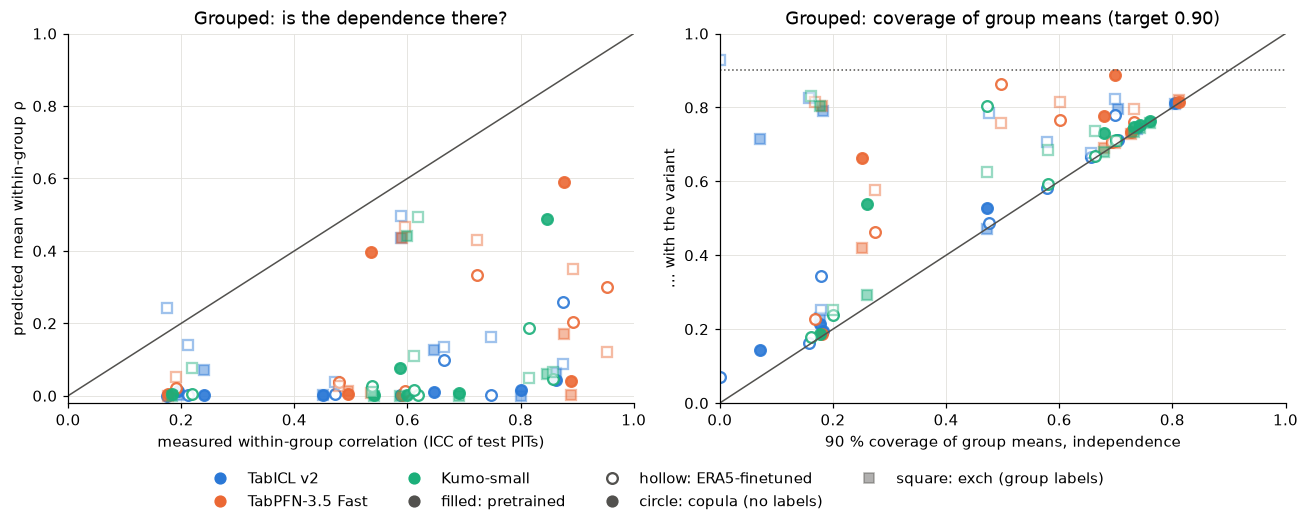

In [4]:
# Grouped tasks: predicted vs measured within-group correlation, and coverage of the group means, per dataset.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
MK = {"indep": ("o", "white"), "copula": ("o", None), "exch": ("s", None)}
for marg, (bk, st) in BA_MARG.items():
    for var in ("copula", "exch"):
        m = ba_paired(marg, var, "grouped")
        mk, fc = MK[var]
        kw = dict(marker=mk, ls="none", ms=7, color=COLORS[bk], mfc=COLORS[bk] if st == "pretrained" else "white",
                  mew=1.5, alpha=0.9 if var == "copula" else 0.45)
        axes[0].plot(m.icc_test_z_v, m.rho_pred_v, **kw)
        axes[1].plot(m.agg_group_cov90_i, m.agg_group_cov90_v, **kw)
axes[0].plot([0, 1], [0, 1], color="#52514e", lw=1)
axes[0].set(xlabel="measured within-group correlation (ICC of test PITs)", ylabel="predicted mean within-group ρ",
            xlim=(0, 1), ylim=(-0.02, 1), title="Grouped: is the dependence there?")
axes[1].plot([0, 1], [0, 1], color="#52514e", lw=1)
axes[1].axhline(0.9, color="#52514e", lw=1, ls=":")
axes[1].set(xlabel="90 % coverage of group means, independence", ylabel="… with the variant", xlim=(0, 1),
            ylim=(0, 1), title="Grouped: coverage of group means (target 0.90)")
handles = [Line2D([], [], marker="o", ls="none", color=COLORS[b], ms=7, label=MARGINAL_NAME[b]) for b in COLORS]
handles += [
    Line2D([], [], marker="o", ls="none", color="#52514e", ms=7, label="filled: pretrained"),
    Line2D([], [], marker="o", ls="none", color="#52514e", mfc="white", mew=1.5, ms=7, label="hollow: ERA5-finetuned"),
    Line2D([], [], marker="o", ls="none", color="#52514e", ms=7, label="circle: copula (no labels)"),
    Line2D([], [], marker="s", ls="none", color="#52514e", alpha=0.45, ms=7, label="square: exch (group labels)"),
]
fig.legend(handles=handles, loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.12))
fig.tight_layout()

### 5.2 Elo ranking on the joint NLL

TabArena's own Elo (`bencheval.evaluator.BenchmarkEvaluator.compute_elo`: Bradley–Terry MLE, 400 scale, 95 % CI from
200 bootstraps over datasets), on BeyondArena's per-dataset aggregation (one match per dataset, its NLL averaged over
splits). Only datasets on which **every** compared method finished every split (no imputation), development datasets
out, `lmm` in the grouped ranking only; Elo 1000 = TabICL v2 ERA5-finetuned, no copula. TabArena's
`context.compare` cannot be used here: it requires every cached baseline on every task. The joint NLL is
marginal + copula, so the ranking across marginals mostly reflects the marginal; read the copula's effect *within* a
marginal (last table). With 5 temporal datasets the wins are nearly separable and the temporal Elo values are not
meaningful (CIs of ±8000): use the mean rank there.

In [5]:
ELO = {s: pd.read_csv(BA / f"compare/joint_nll/{s}.csv") for s in ["all", "iid", "grouped", "temporal"]}
pd.concat({s: e.set_index("method")[["elo", "elo-", "elo+", "mean_rank", "winrate"]] for s, e in ELO.items()},
          axis=1).sort_values(("all", "elo"), ascending=False).round(2)

all                                     iid                                 grouped                                 temporal                                  
                      elo   elo-   elo+ mean_rank winrate     elo   elo-   elo+ mean_rank winrate     elo   elo-   elo+ mean_rank winrate      elo    elo-    elo+ mean_rank winrate
method                                                                                                                                                                              
tabpfn-pre+copula  1701.4  127.2  203.9      3.12    0.88  1783.1  143.8  274.6      2.68    0.90  1395.9  180.0  503.3      6.50    0.69   3020.2   163.7  8070.6       1.4    0.98
tabpfn-pre+exch    1692.8  117.5  173.0      3.21    0.87  1718.5  119.7  208.6      3.27    0.87  1525.9  236.5  680.9      4.17    0.82   2822.9   198.6  6185.7       2.2    0.93
tabpfn-pre+indep   1649.5  113.3  168.7      3.70    0.84  1757.1  143.1  271.2      2.91    0.89  1364.0  205.6  371.9      7.17    0.66   2604.7   376.1  4609.2       3.4    0.86
tabicl-pre+exch    1445.4   57.8   63.8      6.64    0.67  1472.6   88.1  107.1      6.30    0.69  1383.8  174.3  186.4      6.75    0.68   2097.4   570.2  1640.4       8.4    0.56
tabpfn-ft+copula   1416.7   75.8   85.7      7.12    0.64  1395.7   74.8  137.3      7.45    0.62  1325.9  192.7  211.6      8.00    0.61   2398.2   284.8  2497.1       5.0    0.76
tabicl-pre+copula  1413.1   69.4   73.4      7.18    0.64  1443.4   86.6  115.2      6.73    0.66  1311.0  204.8  141.3      8.33    0.59   2113.8   609.8  1682.6       8.2    0.58
tabicl-pre+indep   1393.8   79.8   72.6      7.52    0.62  1494.8   83.1  114.3      5.98    0.71  1176.5  247.0  122.3     11.42    0.42   1956.2  2670.8  1663.4      10.0    0.47
tabpfn-ft+exch     1356.6   63.1   88.7      8.17    0.58  1276.5   68.9  119.2      9.34    0.51  1484.6  246.9  773.5      4.83    0.79   2195.6   211.4  2086.0       7.2    0.64
kumo-pre+copula    1306.3   64.4   63.3      9.06    0.53  1280.8   78.3   94.6      9.27    0.51  1209.4  193.3  105.3     10.67    0.46   2229.0   298.2  2486.0       6.8    0.66
kumo-pre+exch      1285.0   64.2   62.7      9.44    0.50  1226.0   70.6  109.0     10.14    0.46  1292.6  108.8   98.2      8.75    0.57   2162.7   249.4  2280.1       7.6    0.61
tabpfn-ft+indep    1281.6   53.7   59.7      9.50    0.50  1273.6   75.2  105.7      9.39    0.51  1209.4  230.4  183.7     10.67    0.46   2047.2   223.0  2052.4       9.0    0.53
kumo-pre+indep     1269.6   66.9   60.1      9.71    0.49  1269.3   83.7  118.9      9.45    0.50  1161.7  263.1   88.1     11.75    0.40   2047.2   335.2  2212.1       9.0    0.53
tabicl-ft+copula   1087.1  127.8  101.6     12.76    0.31  1078.3  190.8  133.4     12.32    0.33  1079.9  344.4  190.6     13.50    0.31   1260.4  6293.8  1462.6      14.2    0.22
tabicl-ft+exch     1084.1  148.9  101.4     12.80    0.31   988.9  238.8  156.9     13.48    0.27  1289.0  325.3  183.7      8.83    0.56   1153.5  7315.4  1216.4      15.0    0.18
tabicl-ft+indep    1000.0  148.7  127.4     14.02    0.23  1000.0  226.9  152.5     13.34    0.27  1000.0  436.3  229.7     15.00    0.22   1000.0  7292.5    84.5      16.2    0.11
kumo-ft+copula      920.0  113.4   67.8     15.03    0.17   797.4  227.8   86.9     15.50    0.15  1054.6  326.2   95.0     14.00    0.28   1179.2  4492.0    84.1      14.8    0.19
kumo-ft+exch        869.9  172.7  102.1     15.59    0.14   607.9  351.2  111.6     16.93    0.06  1202.1  134.7   79.2     10.83    0.45   1052.3  6541.2    80.8      15.8    0.13
kumo-ft+indep       780.8  146.1   87.6     16.44    0.09   670.1  289.0  100.6     16.52    0.09   913.5  507.3  136.2     16.33    0.15    914.2  8545.4    83.6      16.8    0.07
lmm+lmm               NaN    NaN    NaN       NaN     NaN     NaN    NaN    NaN       NaN     NaN  1127.6  724.6  365.1     12.50    0.36      NaN     NaN     NaN       NaN     NaN

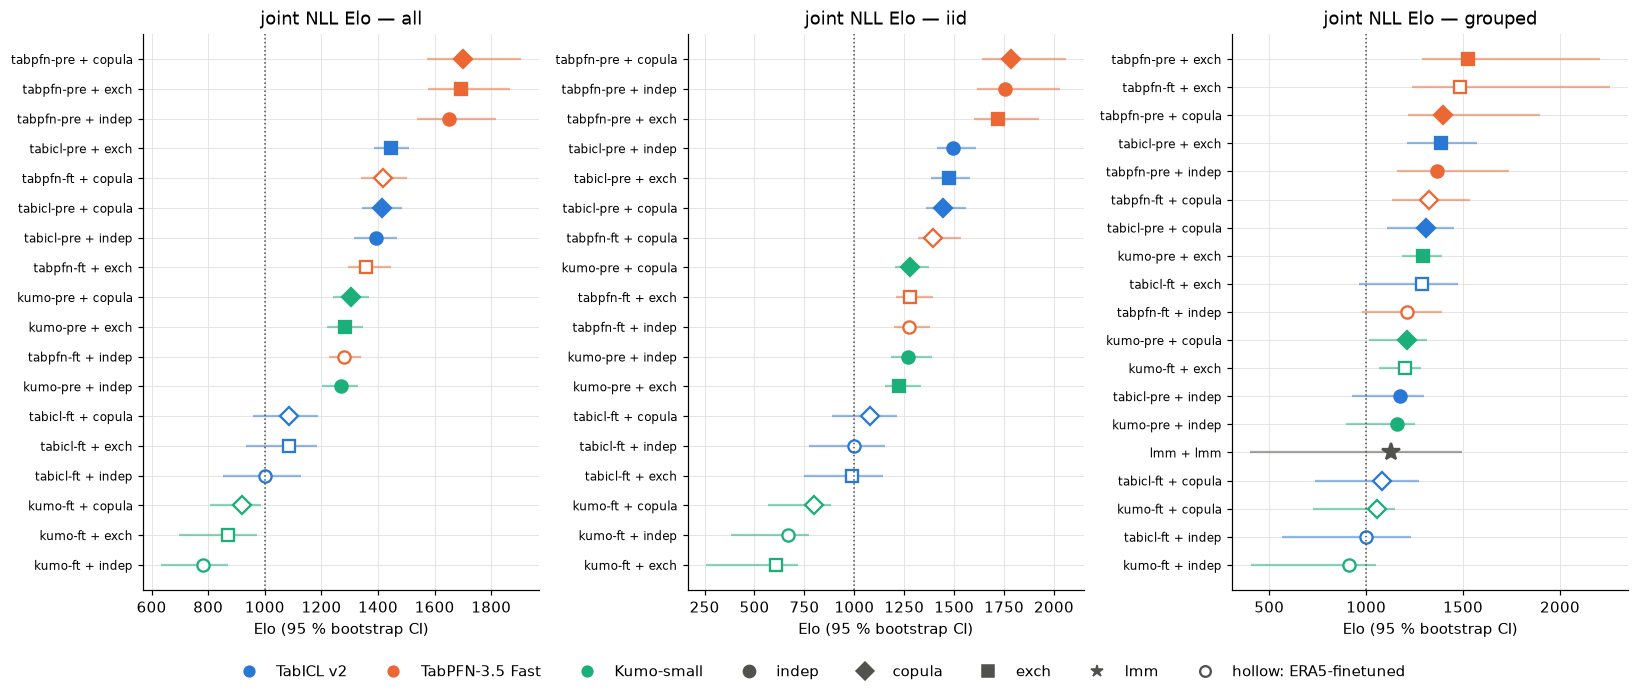

In [6]:
VAR_MK = {"indep": "o", "copula": "D", "exch": "s", "lmm": "*"}
fig, axes = plt.subplots(1, 3, figsize=(15, 6), sharey=False)
for ax, scope in zip(axes, ["all", "iid", "grouped"]):
    e = ELO[scope].sort_values("elo")
    y = np.arange(len(e))
    for yi, (_, r) in zip(y, e.iterrows()):
        marg, var = r["method"].split("+")
        col = COLORS[BA_MARG[marg][0]] if marg in BA_MARG else "#52514e"
        pre = marg.endswith("-pre") or marg == "lmm"
        ax.errorbar(r["elo"], yi, xerr=[[r["elo-"]], [r["elo+"]]], fmt="none", ecolor=col, alpha=0.5, lw=1.5)
        ax.plot(r["elo"], yi, VAR_MK[var], ms=8 if var != "lmm" else 12, color=col, mfc=col if pre else "white",
                mew=1.5)
    ax.set_yticks(y, [m.replace("+", " + ") for m in e["method"]], fontsize=8)
    ax.axvline(1000, color="#52514e", lw=1, ls=":")
    ax.set(title=f"joint NLL Elo — {scope}", xlabel="Elo (95 % bootstrap CI)")
handles = [Line2D([], [], marker="o", ls="none", color=COLORS[b], ms=7, label=MARGINAL_NAME[b]) for b in COLORS]
handles += [Line2D([], [], marker=VAR_MK[v], ls="none", color="#52514e", ms=8, label=v) for v in VAR_MK]
handles += [Line2D([], [], marker="o", ls="none", color="#52514e", mfc="white", mew=1.5, ms=7,
                   label="hollow: ERA5-finetuned")]
fig.legend(handles=handles, loc="lower center", ncol=8, bbox_to_anchor=(0.5, -0.06))
fig.tight_layout()

In [7]:
# The copula's (and exch's) Elo minus the same marginal's independence Elo, per scope (temporal: not meaningful).
gain = {}
for s, e in ELO.items():
    elo = e.set_index("method")["elo"]
    for marg in BA_MARG:
        for var in ("copula", "exch"):
            if f"{marg}+{var}" in elo and f"{marg}+indep" in elo:
                gain[(ba_label(marg), var), s] = elo[f"{marg}+{var}"] - elo[f"{marg}+indep"]
pd.Series(gain).unstack()[["all", "iid", "grouped", "temporal"]].round(0)

,all,iid,grouped,temporal
"(Kumo-small, ERA5-finetuned, copula)",139.0,127.0,141.0,265.0
"(Kumo-small, ERA5-finetuned, exch)",89.0,-62.0,289.0,138.0
"(Kumo-small, pretrained, copula)",37.0,12.0,48.0,182.0
"(Kumo-small, pretrained, exch)",15.0,-43.0,131.0,115.0
"(TabICL v2, ERA5-finetuned, copula)",87.0,78.0,80.0,260.0
"(TabICL v2, ERA5-finetuned, exch)",84.0,-11.0,289.0,154.0
"(TabICL v2, pretrained, copula)",19.0,-51.0,134.0,158.0
"(TabICL v2, pretrained, exch)",52.0,-22.0,207.0,141.0
"(TabPFN-3.5 Fast, ERA5-finetuned, copula)",135.0,122.0,116.0,351.0
"(TabPFN-3.5 Fast, ERA5-finetuned, exch)",75.0,3.0,275.0,148.0


### 5.3 The mixed model (group-aware, own marginals) on the grouped datasets

Random intercept per group, OLS fixed effects on principal axes of the features, REML variance components; for
the new test groups $y_i \sim \mathcal N(f_i^\top\hat\beta, \hat s_u^2 + \hat s_e^2)$ with within-group correlation
$\rho = \hat s_u^2/(\hat s_u^2 + \hat s_e^2)$. Fixed on 2026-11-19 (deviation 9): REML's GLS fixed effects diverged on
two datasets (NLL $\approx 10^{12}$); the mean is now the OLS one. Compared on the **total** joint NLL, since its
marginals differ from the foundation models'.

In [8]:
LMM = BA_D[(BA_D.marginal == "lmm")].set_index("ds")
ref = {
    "lmm": LMM,
    "TabICL v2 ft, indep": BA_D[(BA_D.marginal == "tabicl-ft") & (BA_D.variant == "indep")].set_index("ds"),
    "TabICL v2 ft, copula": BA_D[(BA_D.marginal == "tabicl-ft") & (BA_D.variant == "copula")].set_index("ds"),
    "TabICL v2 ft, exch": BA_D[(BA_D.marginal == "tabicl-ft") & (BA_D.variant == "exch")].set_index("ds"),
    "TabPFN ft, copula": BA_D[(BA_D.marginal == "tabpfn-ft") & (BA_D.variant == "copula")].set_index("ds"),
}
pd.concat({k: v[["rmse", "joint_nll", "agg_group_cov90", "rho_pred", "icc_test_z"]] for k, v in ref.items()},
          axis=1).swaplevel(axis=1).sort_index(axis=1, level=0, sort_remaining=False).round(3)

agg_group_cov90                                                                               icc_test_z                                           \
                                                     lmm TabICL v2 ft, indep TabICL v2 ft, copula TabICL v2 ft, exch TabPFN ft, copula        lmm TabICL v2 ft, indep TabICL v2 ft, copula   
ds                                                                                                                                                                                           
5g_energy_consumption                              0.888               0.158                0.162              0.827             0.228      0.746               0.589                0.589   
early_learning_predictors                          0.491               0.578                0.581              0.706             0.759      0.473               0.211                0.211   
electric_motor_temperature_prediction              1.000               0.000                0.071              0.929               NaN      0.327               0.175                0.175   
sat11_hand_algo_runtime                            0.624               0.699                0.780              0.824             0.767      0.830               0.664                0.664   
telemonitoring_parkinsons_biomedical_voi           0.859               0.179                0.344              0.252             0.462      0.827               0.874                0.874   
video_game_fps_prediction                          0.870               0.477                0.487              0.785             0.862      0.994               0.747                0.747   
video_transcoding_time_prediction                  0.829               0.656                0.665              0.678             0.708      0.092               0.472                0.472   
airfoil_self_noise                                   NaN                 NaN                  NaN                NaN               NaN        NaN               0.000                0.000   
allstate_claims_severity                             NaN                 NaN                  NaN                NaN               NaN        NaN               0.001                0.001   
blood_tests_drink_prediction                         NaN                 NaN                  NaN                NaN               NaN        NaN               0.001                0.001   
body_density_prediction                              NaN                 NaN                  NaN                NaN               NaN        NaN              -0.010               -0.010   
cirrhosis_patient_survival_prediction                NaN                 NaN                  NaN                NaN               NaN        NaN              -0.004               -0.004   
concrete_compressive_strength                        NaN                 NaN                  NaN                NaN               NaN        NaN               0.002                0.002   
diamonds                                             NaN                 NaN                  NaN                NaN               NaN        NaN               0.000                0.000   
fiat_500                                             NaN                 NaN                  NaN                NaN               NaN        NaN              -0.001               -0.001   
food_delivery_time                                   NaN                 NaN                  NaN                NaN               NaN        NaN              -0.004               -0.004   
forest_fires                                         NaN                 NaN                  NaN                NaN               NaN        NaN               0.003                0.003   
healthcare_insurance_expenses                        NaN                 NaN                  NaN                NaN               NaN        NaN              -0.001               -0.001   
houses                                             

**Conclusion (2026-11-20; interim: the large tables of TabPFN and Kumo are running, TabICL's maps_router does not
fit in 503 GB).**

- **The copula lowers the joint NLL of every marginal, but by little.** Within each marginal it ranks above
  independence in 23 of 24 (marginal, scope) cells (Elo +19 to +139 over all regimes; the exception: TabICL
  pretrained on IID, −51). Median $\Delta$NLL per point (5.1): $-0.015$ to $-0.18$ on grouped tasks (largest for the finetuned
  TabPFN and Kumo, $-0.18$ and $-0.12$), $-0.003$ to $-0.013$ on temporal tasks (better on every dataset for 5 of 6
  marginals), $0$ to $-0.004$ on IID tasks.
- **Grouped (H2): the copula is group-blind and sees almost none of the group dependence.** Median predicted
  $\bar\rho = 0.003$–$0.12$ against a measured within-group correlation of $0.56$–$0.66$ (5.1 figure: a few
  datasets reach $0.3$–$0.6$, mostly with TabPFN and Kumo pretrained); coverage of group means
  rises only for TabPFN-ft (0.55 → 0.73) and Kumo-ft (0.53 → 0.63). The variogram score on same-group pairs detects
  the small gain (better on 6/6 datasets for 5 marginals, 5/6 for Kumo-ft); the energy score does not (no CI
  excludes 0). The exchangeable reference, which uses the group labels, gains 2–7× more NLL on the same marginals.
- **IID (H3): near-independence.** $\bar\rho \le 0.02$, energy and variogram scores unchanged within ±0.02 %,
  except TabPFN-finetuned (ES +0.016 % worse, coverage of 32-row blocks 0.88 → 0.94: slight spurious correlation).
- **The marginal dominates the joint NLL.** Every pretrained marginal outranks every ERA5-finetuned one in every
  regime (TabPFN pretrained first, Elo ≈ 1700 vs 1000 for TabICL finetuned), as on CTR23 (§2).
- **The mixed model** (group labels, linear marginals) ranks 15th of 19 on grouped tasks: it models the group
  correlation well (coverage 0.86–0.88 where the groups dominate) but its point predictions are 1.5–5× worse.